<a href="https://colab.research.google.com/github/giacomobarzon/Tesi/blob/main/Tesi_code1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q "dask"
!pip install cdsapi
!pip install cartopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [cdsapi]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 104.9 MB/s  0:00:00


In [59]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
import xarray as xr
import geopandas as gpd
import cartopy.feature as cfeature
import numpy as np
import os
import pandas as pd
from pathlib import Path
import matplotlib.colors as colors
import matplotlib.cm as mcolors
import matplotlib.gridspec as gridspec
from scipy import stats
from matplotlib.ticker import FuncFormatter

In [4]:
BASE_DIR = Path('/content/drive/MyDrive/Tesi')

files = {
    'ERA5': 'era5_monthly_tp.nc',
    'GPCP': 'precip.mon.mean.nc',
    'CHIRPS': 'chirps-v3.0.monthly.nc'
}

paths = {}

for name, filename in files.items():
    matches = list(BASE_DIR.rglob(filename))

    if not matches:
        raise FileNotFoundError(f'{filename} non trovato')

    paths[name] = matches[0]
    print(f'{name}: {matches[0]}')

ERA5: /content/drive/MyDrive/Tesi/era5_monthly_tp.nc
GPCP: /content/drive/MyDrive/Tesi/precip.mon.mean.nc
CHIRPS: /content/drive/MyDrive/Tesi/chirps-v3.0.monthly.nc


In [5]:
ds_era5 = xr.open_dataset(
    paths['ERA5'],
    chunks={'valid_time': 12}
)

ds_gpcp = xr.open_dataset(
    paths['GPCP'],
    chunks={'time': 12}
)

ds_chirps = xr.open_dataset(
    paths['CHIRPS'],
    chunks={
        'time': 12,
        'latitude': 300,
        'longitude': 300
    }
)

datasets = {
    'ERA5': ds_era5,
    'GPCP': ds_gpcp,
    'CHIRPS': ds_chirps
}

/tmp/ipykernel_3126/3920048981.py:1: UserWarning: The specified chunks separate the stored chunks along dimension "valid_time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  ds_era5 = xr.open_dataset(
/tmp/ipykernel_3126/3920048981.py:11: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  ds_chirps = xr.open_dataset(
/tmp/ipykernel_3126/3920048981.py:11: UserWarning: The specified chunks separate the stored chunks along dimension "latitude" starting at index 300. This could degrade performance. Instead, consider rechunking after loading.
  ds_chirps = xr.open_dataset(
/tmp/ipykernel_3126/3920048981.py:11: UserWarning: The specified chunks separate the stored chunks along dimension "longitude" starting at index 300. This could degrade performance. Instead, consider rechunking after loading.
  ds_chirps =

## Define WA domain

In [6]:
# Define West Africa domain

lat_regions = [28, -4]
lon_regions = [-17, 28]

# ERA5: latitude descending, longitude -180 to 180
era5_wa = ds_era5.sel(
    latitude=slice(28, -4),
    longitude=slice(-17, 28)
)

gpcp = ds_gpcp["precip"].assign_coords(
    lon=((ds_gpcp.lon + 180) % 360) - 180
).sortby("lon")

gpcp_region = gpcp.sel(
    lat=slice(-4, 28),
    lon=slice(-17, 28)
)

pr_gpcp = gpcp_region * gpcp_region.time.dt.days_in_month

pr_gpcp.name = "precipitation"
pr_gpcp.attrs["units"] = "mm/month"

# CHIRPS: latitude and longitude ascending
chirps_wa = ds_chirps.sel(
    latitude=slice(-4, 28),
    longitude=slice(-17, 28)
)

datasets_wa = {
    "ERA5": era5_wa,
    "GPCP": gpcp_region,
    "CHIRPS": chirps_wa
}

In [7]:
for name, ds in datasets.items():

    print('\n' + '='*50)
    print(name)
    print('='*50)

    print('Dimensions:', ds.dims)
    print('Coordinates:', list(ds.coords))

    for coord in ds.coords:

        values = ds[coord].values

        print(f'\n{coord}:')
        print('  Shape:', values.shape)

        if values.ndim > 0:
            print('  First value:', values.flat[0])
            print('  Last value:', values.flat[-1])
        else:
            print('  Value:', values.item())


ERA5
Dimensions: FrozenMappingWarningOnValuesAccess({'valid_time': 1021, 'latitude': 285, 'longitude': 273})
Coordinates: ['number', 'valid_time', 'latitude', 'longitude', 'expver']

number:
  Shape: ()
  Value: 0

valid_time:
  Shape: (1021,)
  First value: 1940-01-01T06:00:00.000000000
  Last value: 2025-01-01T06:00:00.000000000

latitude:
  Shape: (285,)
  First value: 37.0
  Last value: -34.0

longitude:
  Shape: (273,)
  First value: -17.0
  Last value: 51.0

expver:
  Shape: (1021,)
  First value: 0001
  Last value: 0005

GPCP
Dimensions: FrozenMappingWarningOnValuesAccess({'time': 552, 'nv': 2, 'lat': 72, 'lon': 144})
Coordinates: ['lat', 'lon', 'time']

lat:
  Shape: (72,)
  First value: -88.75
  Last value: 88.75

lon:
  Shape: (144,)
  First value: 1.25
  Last value: 358.75

time:
  Shape: (552,)
  First value: 1979-01-01T00:00:00.000000000
  Last value: 2024-12-01T00:00:00.000000000

CHIRPS
Dimensions: FrozenMappingWarningOnValuesAccess({'time': 549, 'latitude': 2400, 'long

In [8]:
for name, ds in datasets.items():
    print('\n' + '='*50)
    print(name)
    print('='*50)

    print('Variables:', list(ds.data_vars))

    for var in ds.data_vars:
        print(f'\nVariable: {var}')
        print('Dimensions:', ds[var].dims)
        print('Shape:', ds[var].shape)
        print('Units:', ds[var].attrs.get('units', 'Not specified'))
        print('Long name:', ds[var].attrs.get('long_name', 'Not specified'))


ERA5
Variables: ['tp']

Variable: tp
Dimensions: ('valid_time', 'latitude', 'longitude')
Shape: (1021, 285, 273)
Units: m
Long name: Total precipitation

GPCP
Variables: ['time_bnds', 'lat_bnds', 'lon_bnds', 'precip']

Variable: time_bnds
Dimensions: ('time', 'nv')
Shape: (552, 2)
Units: Not specified
Long name: Not specified

Variable: lat_bnds
Dimensions: ('lat', 'nv')
Shape: (72, 2)
Units: degrees_north
Long name: Not specified

Variable: lon_bnds
Dimensions: ('lon', 'nv')
Shape: (144, 2)
Units: degrees_east
Long name: Not specified

Variable: precip
Dimensions: ('time', 'lat', 'lon')
Shape: (552, 72, 144)
Units: mm/day
Long name: Average Monthly Rate of Precipitation

CHIRPS
Variables: ['precip']

Variable: precip
Dimensions: ('time', 'latitude', 'longitude')
Shape: (549, 2400, 7200)
Units: mm/month
Long name: Climate Hazards center InfraRed Precipitation with Stations


In [9]:
for name, ds, var in [
    ("ERA5", ds_era5, "tp"),
    ("GPCP", ds_gpcp, "precip"),
    ("CHIRPS", ds_chirps, "precip")
]:
    print(f"\n{name}")

    da = ds[var]

    print("Shape:", da.shape)
    print("Units:", da.attrs.get("units", "Not specified"))


ERA5
Shape: (1021, 285, 273)
Units: m

GPCP
Shape: (552, 72, 144)
Units: mm/day

CHIRPS
Shape: (549, 2400, 7200)
Units: mm/month


In [10]:
for name, ds in datasets_wa.items():

    print("\n" + "="*40)
    print(name)
    print("="*40)

    print("Dimensions:", ds.dims)

    lat = "latitude" if "latitude" in ds.coords else "lat"
    lon = "longitude" if "longitude" in ds.coords else "lon"

    print("Latitude:", float(ds[lat].min()), "to", float(ds[lat].max()))
    print("Longitude:", float(ds[lon].min()), "to", float(ds[lon].max()))


ERA5
Dimensions: FrozenMappingWarningOnValuesAccess({'valid_time': 1021, 'latitude': 129, 'longitude': 181})
Latitude: -4.0 to 28.0
Longitude: -17.0 to 28.0

GPCP
Dimensions: ('time', 'lat', 'lon')
Latitude: -3.75 to 26.25
Longitude: -16.25 to 26.25

CHIRPS
Dimensions: FrozenMappingWarningOnValuesAccess({'time': 549, 'latitude': 640, 'longitude': 900})
Latitude: -3.9750022888183594 to 27.974998474121094
Longitude: -16.975006103515625 to 27.974990844726562


In [11]:
# ERA5: m/day -> mm/month
era5_precip = (
    era5_wa["tp"] * 1000 *
    era5_wa["valid_time"].dt.days_in_month
)

# GPCP: mm/day -> mm/month
gpcp_precip = (
    gpcp_region * gpcp_region.time.dt.days_in_month
)

# CHIRPS: already in mm/month
chirps_precip = chirps_wa["precip"]

# Store precipitation datasets
precipitation = {
    "ERA5": era5_precip,
    "GPCP": gpcp_precip,
    "CHIRPS": chirps_precip
}

In [12]:
for name, da in precipitation.items():

    print("\n" + "="*40)
    print(name)
    print("="*40)

    print("Shape:", da.shape)
    print("Units:", da.attrs.get("units", "Not specified"))
    print("Dimensions:", da.dims)


ERA5
Shape: (1021, 129, 181)
Units: m
Dimensions: ('valid_time', 'latitude', 'longitude')

GPCP
Shape: (552, 13, 18)
Units: mm/day
Dimensions: ('time', 'lat', 'lon')

CHIRPS
Shape: (549, 640, 900)
Units: mm/month
Dimensions: ('time', 'latitude', 'longitude')


In [13]:
# Update units after conversion

era5_precip.attrs["units"] = "mm/month"
gpcp_precip.attrs["units"] = "mm/month"
chirps_precip.attrs["units"] = "mm/month"

era5_precip.attrs["long_name"] = "Monthly total precipitation"
gpcp_precip.attrs["long_name"] = "Monthly total precipitation"
chirps_precip.attrs["long_name"] = "Monthly total precipitation"

In [14]:
era5_precip = era5_precip.rename({"valid_time": "time"})

precipitation = {
    "ERA5": era5_precip,
    "GPCP": gpcp_precip,
    "CHIRPS": chirps_precip
}

In [15]:
for name, da in precipitation.items():

    print("\n" + "="*40)
    print(name)
    print("="*40)

    print("Start:", da.time.values[0])
    print("End:", da.time.values[-1])
    print("Number of months:", da.sizes["time"])


ERA5
Start: 1940-01-01T06:00:00.000000000
End: 2025-01-01T06:00:00.000000000
Number of months: 1021

GPCP
Start: 1979-01-01T00:00:00.000000000
End: 2024-12-01T00:00:00.000000000
Number of months: 552

CHIRPS
Start: 1981-01-01T00:00:00.000000000
End: 2026-09-01T00:00:00.000000000
Number of months: 549


In [16]:
# Normalize time coordinates and select common period

for name, da in precipitation.items():

    monthly_time = pd.DatetimeIndex(
        da.time.values
    ).to_period("M").to_timestamp()

    da = da.assign_coords(time=monthly_time)

    precipitation[name] = da.sel(
        time=slice("1981-01-01", "2024-12-31")
    )

In [17]:
# Find common time coordinates

common_time = precipitation["ERA5"].time.to_index()

for name in ["GPCP", "CHIRPS"]:
    common_time = common_time.intersection(
        precipitation[name].time.to_index()
    )

common_time = common_time.sort_values()

for name in precipitation:
    precipitation[name] = precipitation[name].sel(
        time=common_time
    )

print("Common period:", common_time[0], "to", common_time[-1])
print("Number of common months:", len(common_time))

Common period: 1981-01-01 00:00:00 to 2024-12-01 00:00:00
Number of common months: 528


In [18]:
for name, da in precipitation.items():
    print(
        name,
        "| Shape:", da.shape,
        "| Start:", da.time.values[0],
        "| End:", da.time.values[-1]
    )

ERA5 | Shape: (528, 129, 181) | Start: 1981-01-01T00:00:00.000000000 | End: 2024-12-01T00:00:00.000000000
GPCP | Shape: (528, 13, 18) | Start: 1981-01-01T00:00:00.000000000 | End: 2024-12-01T00:00:00.000000000
CHIRPS | Shape: (528, 640, 900) | Start: 1981-01-01T00:00:00.000000000 | End: 2024-12-01T00:00:00.000000000


## Climate index preparation

In [19]:
import cdsapi
from google.colab import userdata

URL = "https://cds.climate.copernicus.eu/api"
KEY = userdata.get("cdskey")

client = cdsapi.Client(url=URL, key=KEY)

2026-11-24 08:25:34,547 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


In [20]:
# Open ERA5 SST and MSLP datasets

ds_sst = xr.open_dataset(BASE_DIR / "era5_monthly_sst.nc")

ds_msl = xr.open_dataset(BASE_DIR / "era5_monthly_msl.nc")

print("SST dataset:")
print(ds_sst)

print("\nMSLP dataset:")
print(ds_msl)

SST dataset:
<xarray.Dataset> Size: 1GB
Dimensions:     (valid_time: 528, latitude: 481, longitude: 1440)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 4kB 1981-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 60.0 59.75 59.5 ... -59.5 -59.75 -60.0
  * longitude   (longitude) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
    number      int64 8B ...
    expver      (valid_time) <U4 8kB ...
Data variables:
    sst         (valid_time, latitude, longitude) float32 1GB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-10T12:43 GRIB to CDM+CF via cfgrib-0.9.1...

MSLP dataset:
<xarray.Dataset> Size: 265MB
Dimensions:     (valid_time: 528, latitude: 241, longitude: 521)
Coordinates:
  * valid_time  (valid_

In [21]:
# Convert SST from Kelvin to Celsius
sst = ds_sst["sst"] - 273.15

# Monthly climatology (1981-2014)
sst_climatology = (
    sst.sel(valid_time=slice("1981-01-01", "2014-12-31"))
    .groupby("valid_time.month")
    .mean("valid_time")
)

# Calculate SST anomalies
sst_anomalies = sst.groupby("valid_time.month") - sst_climatology

print(sst_anomalies)

<xarray.DataArray 'sst' (valid_time: 528, latitude: 481, longitude: 1440)> Size: 1GB
array([[[-0.43376613, -0.43793082, -0.41239667, ..., -0.34869027,
         -0.39028037, -0.42925668],
        [-0.2836914 , -0.29113054, -0.28116393, ..., -0.20295262,
         -0.24055028, -0.27651072],
        [-0.02225995, -0.04601336, -0.09033203, ...,  0.04483569,
          0.02381086, -0.00476789],
        ...,
        [ 0.89453125,  0.9518323 ,  1.007669  , ...,  0.7577262 ,
          0.79408884,  0.83751726],
        [ 0.9578643 ,  1.0157685 ,  1.0581055 , ...,  0.86081123,
          0.88315725,  0.90366507],
        [ 0.94976425,  0.98704624,  1.0074105 , ...,  0.88680506,
          0.898294  ,  0.9128561 ]],

       [[-0.25586653, -0.29380894, -0.27433503, ..., -0.17153752,
         -0.1945442 , -0.21841252],
        [-0.25425816, -0.2885239 , -0.2949865 , ..., -0.13971305,
         -0.18018293, -0.22108364],
        [-0.23294604, -0.2909366 , -0.33735204, ..., -0.07370889,
         -0.135261

In [22]:
# ATL3 region
atl3_region = sst_anomalies.sel(
    latitude=slice(3, -3),
    longitude=slice(-20, 0)
)

# Latitude-weighted spatial mean
weights = np.cos(np.deg2rad(atl3_region.latitude))

atl3 = atl3_region.weighted(weights).mean(
    dim=("latitude", "longitude")
)

atl3.name = "ATL3"
atl3.attrs["units"] = "°C"

print(atl3)

<xarray.DataArray 'ATL3' (valid_time: 528)> Size: 4kB
array([-5.04018231e-01, -3.44279125e-01, -3.26464328e-01, -2.08548123e-01,
       -2.74736913e-01, -1.91060143e-02, -3.40781805e-01, -1.87549593e-01,
       -6.24822484e-03,  3.00106580e-01,  6.23950943e-01,  5.41264932e-01,
        5.15484492e-01,  2.92781873e-01,  4.71108023e-01, -2.05225290e-01,
       -3.87257620e-01, -8.82098304e-01, -9.24723154e-01, -8.55684900e-01,
       -4.85080838e-01, -5.67186237e-01, -5.08515182e-01, -5.62599498e-01,
       -5.17608617e-01,  8.93338195e-02, -6.04805588e-01, -6.56472344e-01,
       -7.68962091e-01, -9.39739597e-01, -5.43212673e-01, -2.04433053e-01,
       -4.18185673e-01, -6.83902084e-01, -6.35096691e-01, -1.41939303e-01,
        3.85032327e-02,  8.27667591e-02,  5.30706068e-01,  4.26117207e-01,
        4.00576445e-01,  4.83967014e-01,  4.89984254e-01,  7.00606614e-01,
        7.11853165e-01,  3.67092164e-01,  4.36053700e-01,  3.18865899e-01,
        3.22241500e-02, -1.94055351e-02, -3.61

In [23]:
# Nino 3.4 region
nino34_region = sst_anomalies.sel(
    latitude=slice(5, -5),
    longitude=slice(-170, -120)
)

# Latitude-weighted spatial mean
weights = np.cos(np.deg2rad(nino34_region.latitude))

nino34 = nino34_region.weighted(weights).mean(
    dim=("latitude", "longitude")
)

nino34.name = "Nino 3.4"
nino34.attrs["units"] = "°C"

print(nino34)

<xarray.DataArray 'Nino 3.4' (valid_time: 528)> Size: 4kB
array([-9.64907543e-01, -1.09461858e+00, -7.74100230e-01, -7.99641522e-01,
       -5.87612258e-01, -6.41634680e-01, -3.89613515e-01, -5.70610028e-01,
       -4.52951826e-01, -4.80528030e-01, -4.11163734e-01, -2.55953581e-01,
       -9.53576773e-02, -1.70105612e-02,  1.77176735e-01,  6.46789242e-01,
        8.43528784e-01,  9.84901488e-01,  8.70385841e-01,  1.22404492e+00,
        1.61710055e+00,  2.12998890e+00,  2.54499278e+00,  2.74672536e+00,
        2.83180557e+00,  2.23390387e+00,  1.75432723e+00,  1.11904986e+00,
        9.22987972e-01,  5.68777100e-01, -1.65131903e-01, -4.16979512e-01,
       -4.40338636e-01, -7.78846418e-01, -1.02271144e+00, -9.83814782e-01,
       -5.39250740e-01, -4.32055796e-01, -5.53008033e-01, -4.13021253e-01,
       -4.09489916e-01, -9.77375345e-01, -6.05502703e-01, -4.17825620e-01,
       -2.62554019e-01, -7.93148167e-01, -1.25403352e+00, -1.23586731e+00,
       -9.25775618e-01, -7.01273198e-01, -

In [24]:
# Western Indian Ocean
dmi_west_region = sst_anomalies.sel(
    latitude=slice(10, -10),
    longitude=slice(50, 70)
)

# Southeastern Indian Ocean
dmi_east_region = sst_anomalies.sel(
    latitude=slice(0, -10),
    longitude=slice(90, 110)
)

# Latitude-weighted means
weights_west = np.cos(np.deg2rad(dmi_west_region.latitude))
weights_east = np.cos(np.deg2rad(dmi_east_region.latitude))

dmi_west = dmi_west_region.weighted(weights_west).mean(
    dim=("latitude", "longitude")
)

dmi_east = dmi_east_region.weighted(weights_east).mean(
    dim=("latitude", "longitude")
)

# Dipole Mode Index
dmi = dmi_west - dmi_east

dmi.name = "DMI"
dmi.attrs["units"] = "°C"

print(dmi)

<xarray.DataArray 'DMI' (valid_time: 528)> Size: 4kB
array([ 6.86718433e-02,  4.82654976e-02, -1.54575627e-01,  2.14893067e-01,
       -5.28640306e-01, -1.57649897e-01, -4.98369008e-01, -3.06750703e-01,
       -5.61273061e-01, -2.36664453e-01, -4.02125483e-01, -1.98566427e-01,
       -4.38352882e-01,  2.09578889e-01,  3.77597702e-01,  1.53264594e-01,
        4.82234205e-01,  2.92580233e-01,  5.40701689e-01,  7.58606210e-01,
        1.09909212e+00,  7.36960969e-01,  1.03455795e+00, -2.44988412e-01,
       -4.48303136e-01, -8.49372650e-01, -9.45880898e-01, -8.49020357e-01,
       -1.52290151e-02,  3.39929943e-01,  7.11406473e-01,  5.72872912e-01,
       -2.61731800e-02, -1.66017892e-01, -2.72986869e-01, -4.07184781e-01,
        8.91146819e-03, -1.87454800e-01,  1.44928768e-01,  2.86857667e-01,
       -2.26391244e-01, -4.66429292e-01, -3.81383527e-01, -6.78177700e-01,
       -8.58813048e-01, -5.84749016e-01, -5.63975491e-01, -6.86554896e-01,
       -3.06812332e-01, -2.59291728e-01, -2.298

In [25]:
# North Atlantic region
amv_region = sst_anomalies.sel(
    latitude=slice(60, 0),
    longitude=slice(-80, 0)
)

# Latitude-weighted spatial mean
weights = np.cos(np.deg2rad(amv_region.latitude))

amv_raw = amv_region.weighted(weights).mean(
    dim=("latitude", "longitude")
)

# Remove linear trend
from scipy.signal import detrend

amv = xr.DataArray(
    detrend(amv_raw.values),
    coords={"valid_time": amv_raw.valid_time},
    dims=["valid_time"],
    name="AMV"
)

amv.attrs["units"] = "°C"

print(amv)

<xarray.DataArray 'AMV' (valid_time: 528)> Size: 4kB
array([ 0.18903711,  0.22590967,  0.41324758,  0.26562996,  0.24736592,
        0.29686347,  0.10027446,  0.03480865,  0.12387486,  0.06110846,
        0.21029525,  0.32440932,  0.16713828,  0.15861225,  0.15911668,
        0.02913284, -0.01478438, -0.05576126, -0.21207154, -0.24217096,
       -0.15273357, -0.23157908, -0.22634504, -0.30258162, -0.06833096,
        0.12503818,  0.29356691,  0.26644456,  0.12583956,  0.08888176,
        0.03219919, -0.0199881 ,  0.01283477, -0.01359089,  0.06735182,
        0.17270317,  0.1372792 ,  0.08774715,  0.08665387,  0.06131034,
        0.01287286, -0.31083104, -0.19521222, -0.09422514, -0.00627174,
       -0.21782577, -0.25656763, -0.12857272, -0.13353842, -0.15135114,
       -0.28251964, -0.26908297, -0.32348093, -0.14018965, -0.05553804,
       -0.23180524, -0.21520728, -0.28145387, -0.2574901 , -0.27302375,
       -0.28369802, -0.19916944, -0.2099774 , -0.22596534, -0.15775938,
       -0.2

In [26]:
# Standardize climate indices

atl3_std = (atl3 - atl3.mean("valid_time")) / atl3.std("valid_time")
nino34_std = (nino34 - nino34.mean("valid_time")) / nino34.std("valid_time")
dmi_std = (dmi - dmi.mean("valid_time")) / dmi.std("valid_time")
amv_std = (amv - amv.mean("valid_time")) / amv.std("valid_time")

# Rename indices
atl3_std.name = "ATL3"
nino34_std.name = "Nino 3.4"
dmi_std.name = "DMI"
amv_std.name = "AMV"

# Set units
for index in [atl3_std, nino34_std, dmi_std, amv_std]:
    index.attrs["units"] = "standard deviations"

# Check results
for index in [atl3_std, nino34_std, dmi_std, amv_std]:
    print(
        f"{index.name}: mean = {float(index.mean()):.3f}, "
        f"std = {float(index.std()):.3f}"
    )

ATL3: mean = -0.000, std = 1.000
Nino 3.4: mean = -0.000, std = 1.000
DMI: mean = 0.000, std = 1.000
AMV: mean = -0.000, std = 1.000


## Climate index

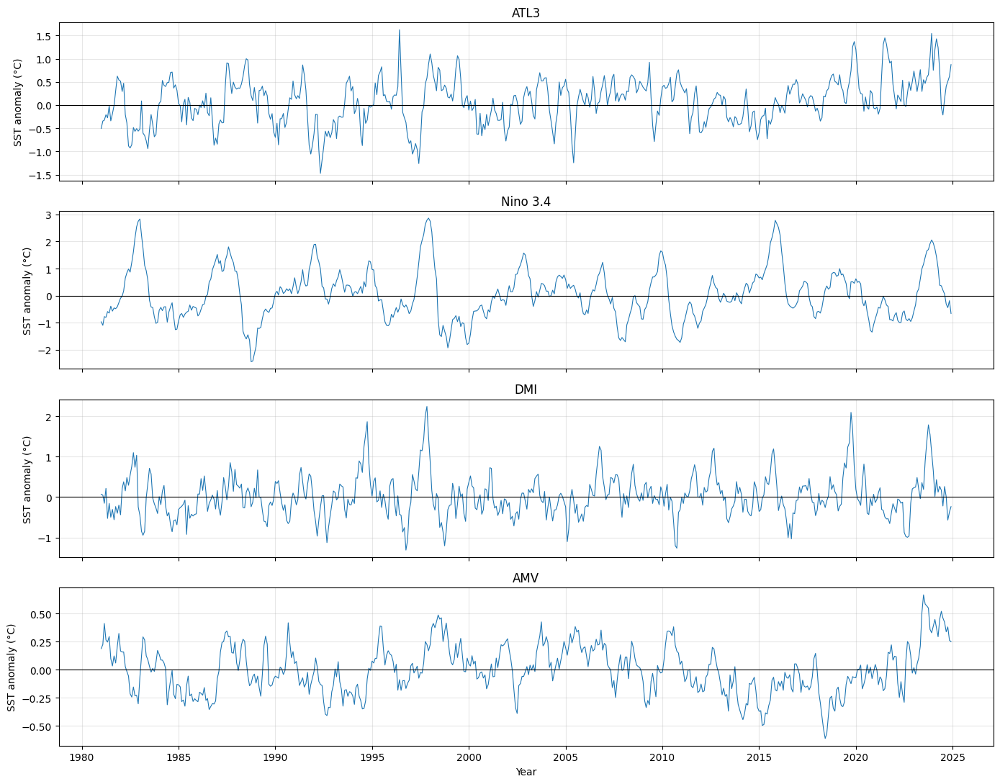

In [27]:
indices_sst = {
    "ATL3": atl3,
    "Nino 3.4": nino34,
    "DMI": dmi,
    "AMV": amv
}

fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

for ax, (name, index) in zip(axes, indices_sst.items()):
    ax.plot(index.valid_time, index, linewidth=0.8)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_ylabel("SST anomaly (°C)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Year")

plt.tight_layout()
plt.show()

In [28]:
# Convert MSLP from Pa to hPa
msl = ds_msl["msl"] / 100

# Monthly climatology (1981-2014)
msl_climatology = (
    msl.sel(valid_time=slice("1981-01-01", "2014-12-31"))
    .groupby("valid_time.month")
    .mean("valid_time")
)

# Calculate MSLP anomalies
msl_anomalies = msl.groupby("valid_time.month") - msl_climatology

print(msl_anomalies)

# Azores region
azores_region = msl_anomalies.sel(
    latitude=slice(40, 36),
    longitude=slice(-28, -20)
)

# Iceland region
iceland_region = msl_anomalies.sel(
    latitude=slice(70, 63),
    longitude=slice(-25, -15)
)

# Latitude-weighted means
weights_azores = np.cos(np.deg2rad(azores_region.latitude))
weights_iceland = np.cos(np.deg2rad(iceland_region.latitude))

azores_msl = azores_region.weighted(weights_azores).mean(
    dim=("latitude", "longitude")
)

iceland_msl = iceland_region.weighted(weights_iceland).mean(
    dim=("latitude", "longitude")
)

# NAO index
nao = azores_msl - iceland_msl

nao.name = "NAO"
nao.attrs["units"] = "hPa"

print(nao)

<xarray.DataArray 'msl' (valid_time: 528, latitude: 241, longitude: 521)> Size: 265MB
array([[[ 2.1450195e+00,  2.1176147e+00,  2.0721436e+00, ...,
         -8.5039673e+00, -8.5742188e+00, -8.6459351e+00],
        [ 2.5477295e+00,  2.4537964e+00,  2.3602295e+00, ...,
         -8.4935913e+00, -8.5653076e+00, -8.6372681e+00],
        [ 2.8076172e+00,  2.7809448e+00,  2.7399902e+00, ...,
         -8.4830933e+00, -8.5573120e+00, -8.6303101e+00],
        ...,
        [ 9.5397949e-01,  8.9404297e-01,  8.5223389e-01, ...,
         -6.4276123e-01, -6.4050293e-01, -6.1688232e-01],
        [ 9.6893311e-01,  8.9965820e-01,  8.5681152e-01, ...,
         -6.4282227e-01, -6.4147949e-01, -6.2158203e-01],
        [ 9.7406006e-01,  8.9715576e-01,  8.4844971e-01, ...,
         -6.4825439e-01, -6.3610840e-01, -6.2066650e-01]],

       [[-1.3922729e+00, -1.4247437e+00, -1.4318237e+00, ...,
          1.6183472e+00,  1.6217041e+00,  1.6241455e+00],
        [-1.1011353e+00, -1.1613770e+00, -1.2221680e+00, ..

Mean: 2.901719268906659e-17
Standard deviation: 0.9999999999999997


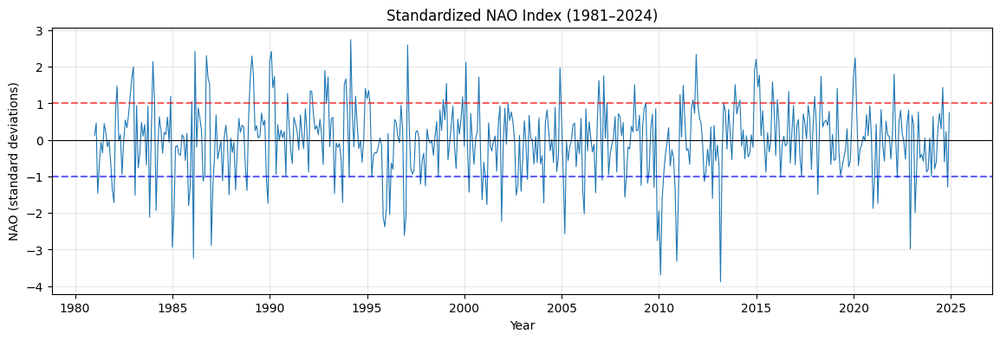

In [29]:
# Standardize NAO index
nao_std = (nao - nao.mean("valid_time")) / nao.std("valid_time")

nao_std.name = "NAO"
nao_std.attrs["units"] = "standard deviations"

print("Mean:", float(nao_std.mean()))
print("Standard deviation:", float(nao_std.std()))

plt.figure(figsize=(14, 4))

plt.plot(nao_std.valid_time, nao_std, linewidth=0.8)

plt.axhline(0, color="black", linewidth=0.8)
plt.axhline(1, color="red", linestyle="--", alpha=0.6)
plt.axhline(-1, color="blue", linestyle="--", alpha=0.6)

plt.title("Standardized NAO Index (1981–2024)")
plt.ylabel("NAO (standard deviations)")
plt.xlabel("Year")
plt.grid(alpha=0.3)

plt.show()

In [30]:
# Combine standardized climate indices

indices = xr.Dataset({
    "ATL3": atl3_std,
    "Nino34": nino34_std,
    "DMI": dmi_std,
    "AMV": amv_std,
    "NAO": nao_std
})

# Check dimensions and time coverage
print(indices)
print("\nTime period:", str(indices.valid_time.values[0]), "to", str(indices.valid_time.values[-1]))
print("Number of months:", indices.sizes["valid_time"])

<xarray.Dataset> Size: 42kB
Dimensions:     (valid_time: 528)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 4kB 1981-01-01 ... 2024-12-01
    number      (valid_time) int64 4kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    expver      (valid_time) <U4 8kB '0001' '0001' '0001' ... '0001' '0001'
    month       (valid_time) int64 4kB 1 2 3 4 5 6 7 8 9 ... 5 6 7 8 9 10 11 12
Data variables:
    ATL3        (valid_time) float64 4kB -1.179 -0.8531 -0.8168 ... 1.108 1.63
    Nino34      (valid_time) float64 4kB -1.089 -1.228 ... -0.2537 -0.7607
    DMI         (valid_time) float64 4kB 0.0962 0.05645 ... -0.7627 -0.4997
    AMV         (valid_time) float64 4kB 0.8826 1.055 1.929 ... 1.231 1.169
    NAO         (valid_time) float64 4kB 0.1288 0.4624 -1.458 ... -1.285 0.7416

Time period: 1981-01-01T00:00:00.000000000 to 2024-12-01T00:00:00.000000000
Number of months: 528


In [31]:
# Common period
start = "1981-01-01"
end = "2024-12-31"

# ERA5
era5_region = ds_era5["tp"].sel(
    valid_time=slice(start, end),
    latitude=slice(28, -4),
    longitude=slice(-17, 28)
)

pr_era5 = era5_region * 1000 * era5_region.valid_time.dt.days_in_month
pr_era5.name = "precipitation"
pr_era5.attrs["units"] = "mm/month"

# GPCP
gpcp = ds_gpcp["precip"].assign_coords(
    lon=((ds_gpcp.lon + 180) % 360) - 180
).sortby("lon")

gpcp_region = gpcp.sel(
    time=slice(start, end),
    lat=slice(-4, 28),
    lon=slice(-17, 28)
)

pr_gpcp = gpcp_region * gpcp_region.time.dt.days_in_month
pr_gpcp.name = "precipitation"
pr_gpcp.attrs["units"] = "mm/month"

# CHIRPS
chirps_region = ds_chirps["precip"].sel(
    time=slice(start, end),
    latitude=slice(-4, 28),
    longitude=slice(-17, 28)
)

pr_chirps = chirps_region.copy()
pr_chirps.name = "precipitation"
pr_chirps.attrs["units"] = "mm/month"

# Check
for name, data in {
    "ERA5": pr_era5,
    "GPCP": pr_gpcp,
    "CHIRPS": pr_chirps
}.items():

    print(f"\n{name}")
    print("Dimensions:", data.dims)
    print("Shape:", data.shape)


ERA5
Dimensions: ('valid_time', 'latitude', 'longitude')
Shape: (528, 129, 181)

GPCP
Dimensions: ('time', 'lat', 'lon')
Shape: (528, 13, 18)

CHIRPS
Dimensions: ('time', 'latitude', 'longitude')
Shape: (528, 640, 900)


In [32]:
# Rename ERA5 time coordinate
pr_era5 = pr_era5.rename({"valid_time": "time"})

# Set all timestamps to the first day of each month
pr_era5 = pr_era5.assign_coords(
    time=pr_era5.time.values.astype("datetime64[M]").astype("datetime64[ns]")
)

pr_gpcp = pr_gpcp.assign_coords(
    time=pr_gpcp.time.values.astype("datetime64[M]").astype("datetime64[ns]")
)

pr_chirps = pr_chirps.assign_coords(
    time=pr_chirps.time.values.astype("datetime64[M]").astype("datetime64[ns]")
)

# Rename indices time coordinate
indices = indices.rename({"valid_time": "time"})

# Check temporal alignment
print("ERA5:", np.array_equal(pr_era5.time.values, indices.time.values))
print("GPCP:", np.array_equal(pr_gpcp.time.values, indices.time.values))
print("CHIRPS:", np.array_equal(pr_chirps.time.values, indices.time.values))

ERA5: True
GPCP: True
CHIRPS: True


In [33]:
# Calculate seasonal (JJAS) precipitation anomalies

def calculate_seasonal_anomalies(data):

    jjas = data.where(data.time.dt.month.isin([6, 7, 8, 9]), drop=True)

    climatology = (
        jjas.sel(time=slice("1981-01-01", "2014-12-31"))
        .groupby("time.year")
        .mean("time")
        .mean("year")
    )

    seasonal_mean = jjas.groupby("time.year").mean("time")

    anomalies = seasonal_mean - climatology

    return anomalies


# Calculate anomalies for each dataset
pr_era5_anom_jjas = calculate_seasonal_anomalies(pr_era5)
pr_gpcp_anom_jjas = calculate_seasonal_anomalies(pr_gpcp)
pr_chirps_anom_jjas = calculate_seasonal_anomalies(pr_chirps)


# Check
for name, data in {
    "ERA5": pr_era5_anom_jjas,
    "GPCP": pr_gpcp_anom_jjas,
    "CHIRPS": pr_chirps_anom_jjas
}.items():
    print(f"\n{name}")
    print("Shape:", data.shape)
    print("Mean anomaly:", float(data.mean().compute()))


ERA5
Shape: (44, 129, 181)
Mean anomaly: -0.09869123646519483

GPCP
Shape: (44, 13, 18)
Mean anomaly: 0.27802230414953416

CHIRPS
Shape: (44, 640, 900)
Mean anomaly: 0.8187234401702881


In [34]:
pr_era5_anom_jjas = calculate_seasonal_anomalies(pr_era5)
pr_gpcp_anom_jjas = calculate_seasonal_anomalies(pr_gpcp)
pr_chirps_anom_jjas = calculate_seasonal_anomalies(pr_chirps)

In [35]:
for name, data in {
    "ERA5": pr_era5_anom_jjas,
    "GPCP": pr_gpcp_anom_jjas,
    "CHIRPS": pr_chirps_anom_jjas
}.items():

    reference_mean = data.sel(year=slice(1991, 2020)).mean().compute()

    print(f"{name}: {float(reference_mean):.6f}")

ERA5: -0.947393
GPCP: 0.378024
CHIRPS: 1.223371


## Compute seasonal correlation

In [36]:
def calculate_seasonal_mean(data):

    jjas = data.where(data.valid_time.dt.month.isin([6, 7, 8, 9]), drop=True)

    seasonal_mean = jjas.groupby("valid_time.year").mean("valid_time")

    return seasonal_mean

In [37]:
indices = {
    "ATL3": atl3,
    "Nino34": nino34,
    "DMI": dmi,
    "AMV": amv,
    "NAO": nao
}

In [38]:
indices_jjas = {
    name: calculate_seasonal_mean(data)
    for name, data in indices.items()
}

In [39]:
for name, data in indices_jjas.items():

    print(f"\n{name}")
    print(data)


ATL3
<xarray.DataArray 'ATL3' (year: 44)> Size: 352B
array([-0.13842141, -0.7868968 , -0.52639275,  0.59660276, -0.11982055,
        0.00593618,  0.68719664,  0.81601579,  0.13263525, -0.28207754,
        0.38782872, -0.83438099, -0.00540797, -0.49598453,  0.49188036,
        0.47758811, -0.56332009,  0.55351867,  0.65464959, -0.52365934,
       -0.28864172, -0.07814941,  0.30618447, -0.21990584, -0.43494154,
        0.19668612,  0.40440794,  0.5202216 , -0.36882543,  0.29883007,
       -0.2008186 ,  0.00954421, -0.35797097, -0.31372442, -0.44263878,
        0.29776075,  0.10419107,  0.34289595,  0.23245653, -0.02337886,
        1.28886053,  0.19286912,  0.47590277,  0.06768207])
Coordinates:
  * year     (year) int64 352B 1981 1982 1983 1984 1985 ... 2021 2022 2023 2024
Attributes: (12/31)
    GRIB_paramId:                             34
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      692640
    GRIB_typeOfLevel:                         

In [40]:
# Pearson correlations: climate indices vs ERA5 precipitation anomalies (JJAS)

era5_correlations_jjas = {}

for index_name, index in indices_jjas.items():

    era5_correlations_jjas[index_name] = xr.corr(
        index,
        pr_era5_anom_jjas,
        dim="year"
    )

    print(f"{index_name}: {era5_correlations_jjas[index_name].shape}")

ATL3: (129, 181)
Nino34: (129, 181)
DMI: (129, 181)
AMV: (129, 181)
NAO: (129, 181)


In [41]:
# Pearson correlations: climate indices vs GPCP precipitation anomalies (JJAS)
gpcp_correlations_jjas = {}

for index_name in ["ATL3", "Nino34", "DMI", "AMV", "NAO"]:

    gpcp_correlations_jjas[index_name] = xr.corr(
        indices_jjas[index_name],
        pr_gpcp_anom_jjas,
        dim="year"
    )

    print(f"{index_name}: {gpcp_correlations_jjas[index_name].shape}")

ATL3: (13, 18)
Nino34: (13, 18)
DMI: (13, 18)
AMV: (13, 18)
NAO: (13, 18)


In [42]:
# Pearson correlations: climate indices vs CHIRPS JJAS precipitation anomalies

chirps_correlations_jjas = {}

for index_name in ["ATL3", "Nino34", "DMI", "AMV", "NAO"]:

    chirps_correlations_jjas[index_name] = xr.corr(
        indices_jjas[index_name],
        pr_chirps_anom_jjas,
        dim="year"
    )

    print(f"{index_name}: {chirps_correlations_jjas[index_name].shape}")

ATL3: (640, 900)
Nino34: (640, 900)
DMI: (640, 900)
AMV: (640, 900)
NAO: (640, 900)


In [43]:
from shapely.ops import unary_union

world = gpd.read_file(
    "https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip"
)

In [44]:
west_africa_countries = [
    "Mauritania",
    "Senegal",
    "Gambia",
    "Guinea-Bissau",
    "Guinea",
    "Sierra Leone",
    "Liberia",
    "Ivory Coast",
    "Ghana",
    "Togo",
    "Benin",
    "Burkina Faso",
    "Mali",
    "Niger",
    "Nigeria",
    "Chad",
    "Gabon",
    "Equatorial Guinea",
    "Cameroon",
    "Central African Republic"
]

In [45]:
# Select West African countries
wa = world[world["ADMIN"].isin(west_africa_countries)].copy()

# Merge all West African countries
wa_union = wa.geometry.union_all()

# Extract only the external boundary
wa_outline = gpd.GeoSeries(
    [wa_union.boundary],
    crs=wa.crs
)

In [50]:
precipitation_datasets = {
    "ERA5": pr_era5,
    "GPCP": pr_gpcp,
    "CHIRPS": pr_chirps
}

precipitation_climatology = {}

for dataset_name, data in precipitation_datasets.items():

    jjas = data.where(
        data.time.dt.month.isin([6, 7, 8, 9]),
        drop=True
    )

    seasonal_mean = jjas.groupby("time.year").mean("time")

    precipitation_climatology[dataset_name] = seasonal_mean.mean("year")

/tmp/ipykernel_3126/1212597407.py:128: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.10, 1, 0.99])


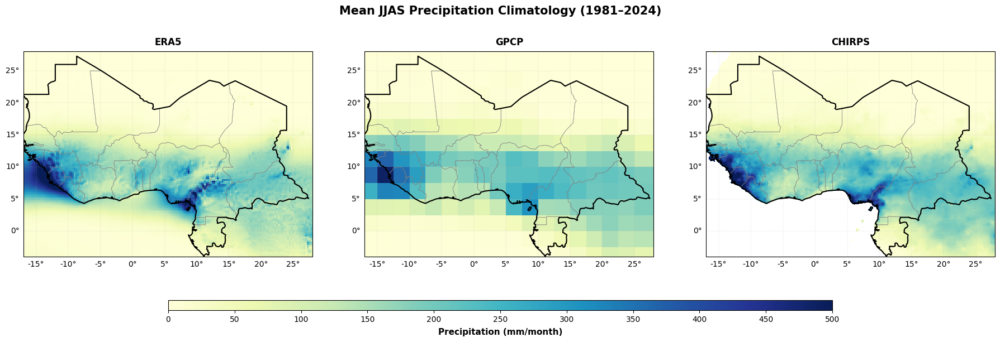

In [65]:

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

for ax, (dataset_name, data) in zip(
    axes, precipitation_climatology.items()
):

    if "longitude" in data.dims:
        lon_dim, lat_dim = "longitude", "latitude"
    else:
        lon_dim, lat_dim = "lon", "lat"

    if dataset_name == "GPCP":

        lon = data[lon_dim].values
        lat = data[lat_dim].values

        lon_edges = np.concatenate([
            [lon_regions[0]],
            (lon[:-1] + lon[1:]) / 2,
            [lon_regions[1]]
        ])

        lat_edges = np.concatenate([
            [lat_regions[1]],
            (lat[:-1] + lat[1:]) / 2,
            [lat_regions[0]]
        ])

        im = ax.pcolormesh(
            lon_edges,
            lat_edges,
            data,
            transform=ccrs.PlateCarree(),
            cmap="YlGnBu",
            vmin=0,
            vmax=500,
            shading="flat"
        )

    else:

        im = ax.pcolormesh(
            data[lon_dim],
            data[lat_dim],
            data,
            transform=ccrs.PlateCarree(),
            cmap="YlGnBu",
            vmin=0,
            vmax=500,
            shading="auto"
        )

    # West Africa external boundary
    ax.add_geometries(
        [wa_union],
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="black",
        linewidth=1.5,
        zorder=4
    )

    # Internal country boundaries
    ax.add_geometries(
        wa.geometry,
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="grey",
        linewidth=0.4,
        zorder=3
    )

    ax.set_extent(
        [-17, 28, -4, 28],
        crs=ccrs.PlateCarree()
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.3,
        alpha=0.5,
        linestyle="--",
        xlocs=np.arange(-15, 28, 5),
        ylocs=np.arange(0, 28, 5)
    )

    gl.xformatter = FuncFormatter(lambda x, pos: f"{x:.0f}°")
    gl.yformatter = FuncFormatter(lambda y, pos: f"{y:.0f}°")

    gl.top_labels = False
    gl.right_labels = False

    ax.set_title(
        dataset_name,
        fontsize=12,
        pad=8,
        fontweight="bold"
    )

# Shared colorbar
cbar_ax = fig.add_axes([0.17, 0.05, 0.66, 0.03])

cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    orientation="horizontal",
    ticks=np.arange(0, 501, 50)
)

cbar.set_label(
    "Precipitation (mm/month)",
    fontsize=11,
    labelpad=6,
    fontweight="bold"
)

plt.suptitle(
    "Mean JJAS Precipitation Climatology (1981–2024)",
    y=0.96,
    fontsize=15,
    fontweight="bold",
)

plt.tight_layout(rect=[0, 0.10, 1, 0.99])
plt.subplots_adjust(wspace=0.18)

# Save figure
save_dir = "/content/drive/MyDrive/TESI/Climatology"
os.makedirs(save_dir, exist_ok=True)

filename = "Mean_JJAS_Precipitation_Climatology_1981-2024.png"

plt.savefig(
    os.path.join(save_dir, filename),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


/tmp/ipykernel_3126/773927027.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.10, 1, 0.99])


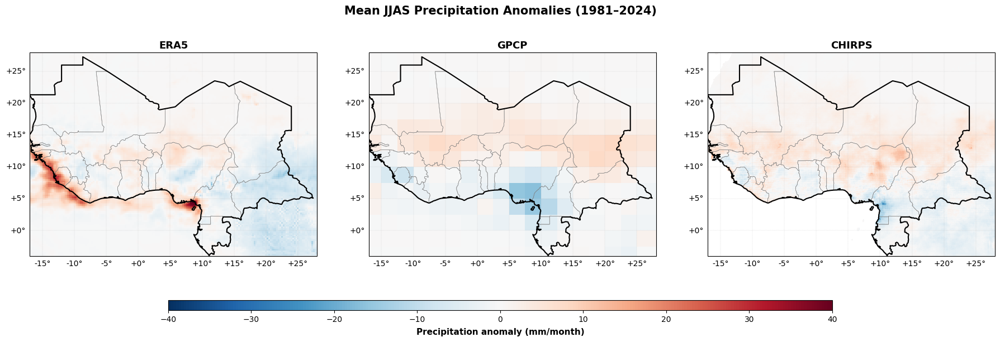

In [66]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

for ax, (dataset_name, data) in zip(
    axes, {
        "ERA5": pr_era5_anom_jjas,
        "GPCP": pr_gpcp_anom_jjas,
        "CHIRPS": pr_chirps_anom_jjas
    }.items()
):

    if "longitude" in data.dims:
        lon_dim, lat_dim = "longitude", "latitude"
    else:
        lon_dim, lat_dim = "lon", "lat"

    if dataset_name == "GPCP":

        lon = data[lon_dim].values
        lat = data[lat_dim].values

        lon_edges = np.concatenate([
            [lon_regions[0]],
            (lon[:-1] + lon[1:]) / 2,
            [lon_regions[1]]
        ])

        lat_edges = np.concatenate([
            [lat_regions[1]],
            (lat[:-1] + lat[1:]) / 2,
            [lat_regions[0]]
        ])

        im = ax.pcolormesh(
            lon_edges,
            lat_edges,
            data.mean("year"),
            transform=ccrs.PlateCarree(),
            cmap="RdBu_r",
            vmin=-40,
            vmax=40,
            shading="flat"
        )

    else:

        im = ax.pcolormesh(
            data[lon_dim],
            data[lat_dim],
            data.mean("year"),
            transform=ccrs.PlateCarree(),
            cmap="RdBu_r",
            vmin=-40,
            vmax=40,
            shading="auto"
        )

    # West Africa external boundary
    ax.add_geometries(
        [wa_union],
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="black",
        linewidth=1.5,
        zorder=4
    )

    # Internal country boundaries
    ax.add_geometries(
        wa.geometry,
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="grey",
        linewidth=0.4,
        zorder=3
    )

    ax.set_extent(
        [-17, 28, -4, 28],
        crs=ccrs.PlateCarree()
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.3,
        alpha=0.5,
        linestyle="--",
        xlocs=np.arange(-15, 28, 5),
        ylocs=np.arange(0, 28, 5)
    )

    gl.top_labels = False
    gl.right_labels = False

    gl.xformatter = FuncFormatter(lambda x, pos: f"{x:+.0f}°")
    gl.yformatter = FuncFormatter(lambda y, pos: f"{y:+.0f}°")

    ax.set_title(
        dataset_name,
        fontsize=13,
        pad=5,
        fontweight="bold"
    )

# Shared horizontal colorbar
cbar_ax = fig.add_axes([0.17, 0.05, 0.66, 0.03])

cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    orientation="horizontal",
    ticks=np.arange(-50, 51, 10)
)

cbar.set_label(
    "Precipitation anomaly (mm/month)",
    fontsize=11,
    labelpad=6,
    fontweight="bold"
)

plt.suptitle(
    "Mean JJAS Precipitation Anomalies (1981–2024)",
    y=0.96,
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.10, 1, 0.99])
plt.subplots_adjust(wspace=0.18)

# Save figure
save_dir = "/content/drive/MyDrive/TESI/Climatology"
os.makedirs(save_dir, exist_ok=True)

filename = "Mean_JJAS_Precipitation_Anomalies_1981-2024.png"

plt.savefig(
    os.path.join(save_dir, filename),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [76]:
# Select the period 1993-2016
pr_era5_anom_9316 = pr_era5_anom_jjas.sel(year=slice(1993, 2016))
pr_gpcp_anom_9316 = pr_gpcp_anom_jjas.sel(year=slice(1993, 2016))
pr_chirps_anom_9316 = pr_chirps_anom_jjas.sel(year=slice(1993, 2016))

In [77]:
mean_anomalies_9316 = {
    "ERA5": pr_era5_anom_9316.mean("year"),
    "GPCP": pr_gpcp_anom_9316.mean("year"),
    "CHIRPS": pr_chirps_anom_9316.mean("year")
}

/tmp/ipykernel_3126/3423360351.py:128: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.10, 1, 0.92])


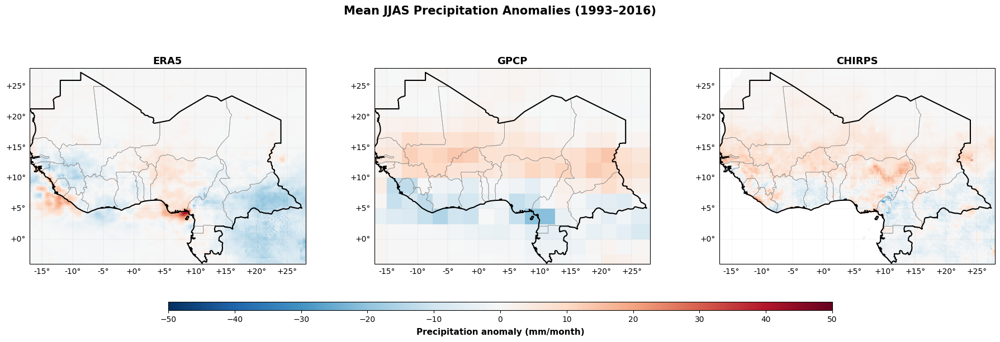

In [78]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

for ax, (dataset_name, data) in zip(
    axes, mean_anomalies_9316.items()
):

    if "longitude" in data.dims:
        lon_dim, lat_dim = "longitude", "latitude"
    else:
        lon_dim, lat_dim = "lon", "lat"

    if dataset_name == "GPCP":

        lon = data[lon_dim].values
        lat = data[lat_dim].values

        lon_edges = np.concatenate([
            [lon_regions[0]],
            (lon[:-1] + lon[1:]) / 2,
            [lon_regions[1]]
        ])

        lat_edges = np.concatenate([
            [lat_regions[1]],
            (lat[:-1] + lat[1:]) / 2,
            [lat_regions[0]]
        ])

        im = ax.pcolormesh(
            lon_edges,
            lat_edges,
            data,
            transform=ccrs.PlateCarree(),
            cmap="RdBu_r",
            vmin=-50,
            vmax=50,
            shading="flat"
        )

    else:

        im = ax.pcolormesh(
            data[lon_dim],
            data[lat_dim],
            data,
            transform=ccrs.PlateCarree(),
            cmap="RdBu_r",
            vmin=-50,
            vmax=50,
            shading="auto"
        )

    # West Africa external boundary
    ax.add_geometries(
        [wa_union],
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="black",
        linewidth=1.5,
        zorder=4
    )

    # Internal country boundaries
    ax.add_geometries(
        wa.geometry,
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="grey",
        linewidth=0.4,
        zorder=3
    )

    ax.set_extent(
        [-17, 28, -4, 28],
        crs=ccrs.PlateCarree()
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.3,
        alpha=0.5,
        linestyle="--",
        xlocs=np.arange(-15, 28, 5),
        ylocs=np.arange(0, 28, 5)
    )

    gl.top_labels = False
    gl.right_labels = False

    gl.xformatter = FuncFormatter(lambda x, pos: f"{x:+.0f}°")
    gl.yformatter = FuncFormatter(lambda y, pos: f"{y:+.0f}°")

    ax.set_title(
        dataset_name,
        fontsize=13,
        pad=5,
        fontweight="bold"
    )

# Shared horizontal colorbar
cbar_ax = fig.add_axes([0.17, 0.05, 0.66, 0.025])

cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    orientation="horizontal",
    ticks=np.arange(-50, 51, 10)
)

cbar.set_label(
    "Precipitation anomaly (mm/month)",
    fontsize=11,
    labelpad=6,
    fontweight="bold"
)

plt.suptitle(
    "Mean JJAS Precipitation Anomalies (1993–2016)",
    y=0.96,
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.10, 1, 0.92])
plt.subplots_adjust(wspace=0.25)

# Save figure
save_dir = "/content/drive/MyDrive/TESI/Climatology"
os.makedirs(save_dir, exist_ok=True)

filename = "Mean_JJAS_Precipitation_Anomalies_1993-2016.png"

plt.savefig(
    os.path.join(save_dir, filename),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [85]:
# Select precipitation anomalies for 1994

pr_era5_anom_2016 = pr_era5_anom_jjas.sel(year=2016)
pr_gpcp_anom_2016 = pr_gpcp_anom_jjas.sel(year=2016)
pr_chirps_anom_2016 = pr_chirps_anom_jjas.sel(year=2016)

In [80]:
for name, data in {
    "ERA5": pr_era5_anom_1994,
    "GPCP": pr_gpcp_anom_1994,
    "CHIRPS": pr_chirps_anom_1994
}.items():

    print(f"\n{name}")
    print("Shape:", data.shape)
    print("Mean anomaly:", float(data.mean().compute()))


ERA5
Shape: (129, 181)
Mean anomaly: 9.32949136212542

GPCP
Shape: (13, 18)
Mean anomaly: 5.672132003398199

CHIRPS
Shape: (640, 900)
Mean anomaly: 4.7474870681762695


/tmp/ipykernel_3126/4168090850.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.10, 1, 0.92])


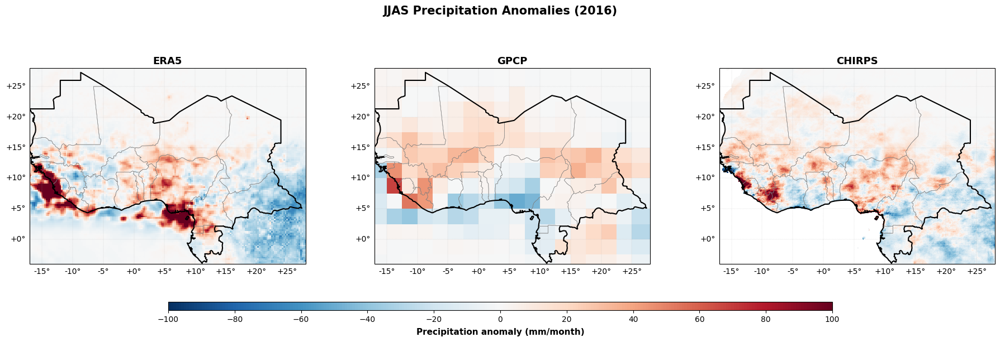

In [86]:
# Plot JJAS precipitation anomalies for 1994

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

for ax, (dataset_name, data) in zip(
    axes, {
        "ERA5": pr_era5_anom_2016,
        "GPCP": pr_gpcp_anom_2016,
        "CHIRPS": pr_chirps_anom_2016
    }.items()
):

    if "longitude" in data.dims:
        lon_dim, lat_dim = "longitude", "latitude"
    else:
        lon_dim, lat_dim = "lon", "lat"

    if dataset_name == "GPCP":

        lon = data[lon_dim].values
        lat = data[lat_dim].values

        lon_edges = np.concatenate([
            [lon_regions[0]],
            (lon[:-1] + lon[1:]) / 2,
            [lon_regions[1]]
        ])

        lat_edges = np.concatenate([
            [lat_regions[1]],
            (lat[:-1] + lat[1:]) / 2,
            [lat_regions[0]]
        ])

        im = ax.pcolormesh(
            lon_edges,
            lat_edges,
            data.values,
            transform=ccrs.PlateCarree(),
            cmap="RdBu_r",
            vmin=-100,
            vmax=100,
            shading="flat"
        )

    else:

        im = ax.pcolormesh(
            data[lon_dim],
            data[lat_dim],
            data,
            transform=ccrs.PlateCarree(),
            cmap="RdBu_r",
            vmin=-100,
            vmax=100,
            shading="auto"
        )

    # West Africa external boundary
    ax.add_geometries(
        [wa_union],
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="black",
        linewidth=1.5,
        zorder=4
    )

    # Internal country boundaries
    ax.add_geometries(
        wa.geometry,
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="grey",
        linewidth=0.4,
        zorder=3
    )

    ax.set_extent(
        [-17, 28, -4, 28],
        crs=ccrs.PlateCarree()
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.3,
        alpha=0.5,
        linestyle="--",
        xlocs=np.arange(-15, 28, 5),
        ylocs=np.arange(0, 28, 5)
    )

    gl.top_labels = False
    gl.right_labels = False

    gl.xformatter = FuncFormatter(lambda x, pos: f"{x:+.0f}°")
    gl.yformatter = FuncFormatter(lambda y, pos: f"{y:+.0f}°")

    ax.set_title(
        dataset_name,
        fontsize=13,
        pad=5,
        fontweight="bold"
    )

# Shared horizontal colorbar
cbar_ax = fig.add_axes([0.17, 0.05, 0.66, 0.025])

cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    orientation="horizontal",
    ticks=np.arange(-100, 101, 20)
)

cbar.set_label(
    "Precipitation anomaly (mm/month)",
    fontsize=11,
    labelpad=6,
    fontweight="bold"
)

plt.suptitle(
    "JJAS Precipitation Anomalies (2016)",
    y=0.96,
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.10, 1, 0.92])
plt.subplots_adjust(wspace=0.25)

# Save figure
save_dir = "/content/drive/MyDrive/TESI/Climatology"
os.makedirs(save_dir, exist_ok=True)

filename = "JJAS_Precipitation_Anomalies_2016.png"

plt.savefig(
    os.path.join(save_dir, filename),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Seasonal Pearson correlations: climate indices vs ERA5 JJAS precipitation anomalies

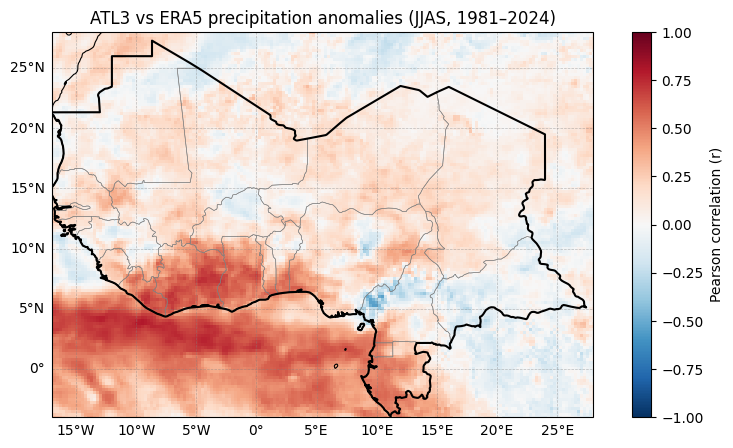

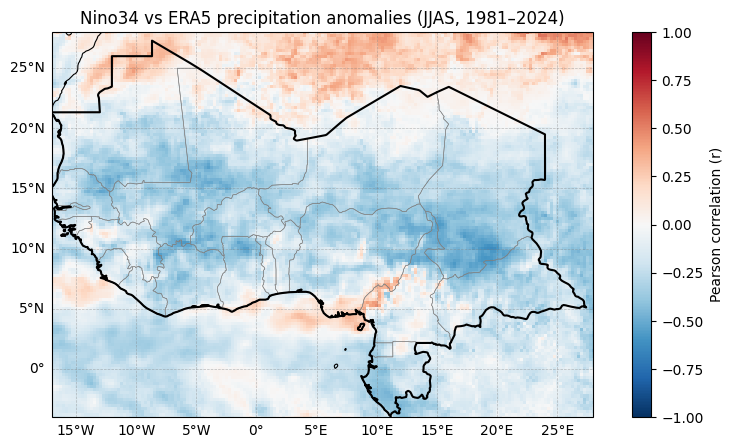

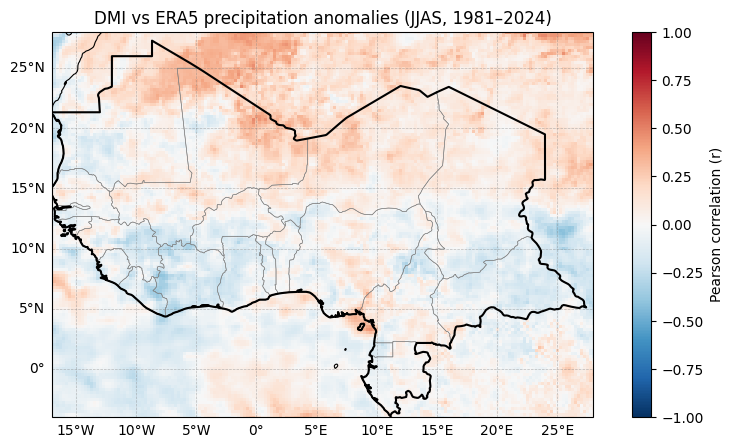

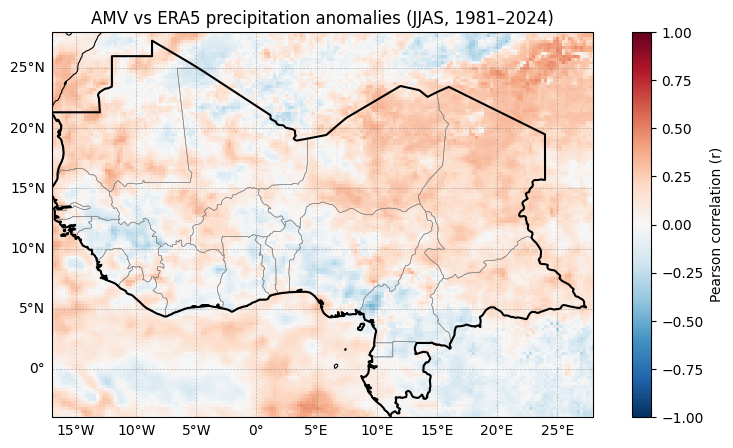

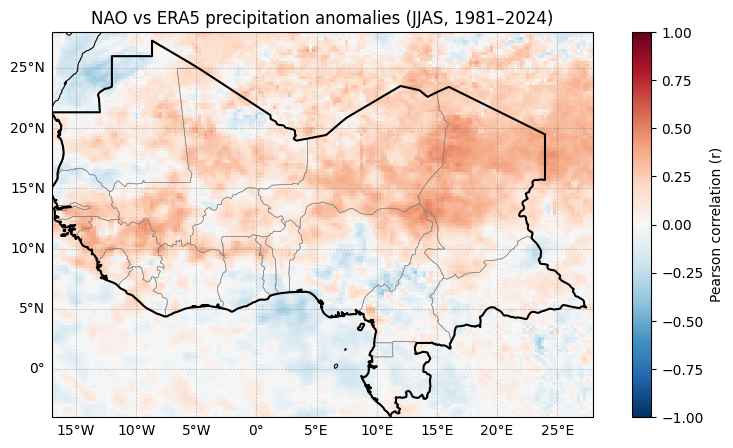

In [ ]:
# Plot ERA5 JJAS correlation maps
save_dir = "/content/drive/MyDrive/TESI/Correlation_maps/ERA5"
os.makedirs(save_dir, exist_ok=True)

for index_name, correlation in era5_correlations_jjas.items():

    fig = plt.figure(figsize=(10, 5))
    ax = plt.axes(projection=ccrs.PlateCarree())

    correlation.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        cbar_kwargs={"label": "Pearson correlation (r)"}
    )

    # Internal country boundaries
    ax.add_geometries(
        wa.geometry,
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="gray",
        linewidth=0.4,
        zorder=3
    )

    # External West Africa boundary
    ax.add_geometries(
        wa_outline.geometry,
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="black",
        linewidth=1.5,
        zorder=4
    )

    ax.coastlines(resolution="50m", linewidth=0.8, zorder=3)

    # West Africa domain
    ax.set_extent(
        [lon_regions[0], lon_regions[1],
         lat_regions[1], lat_regions[0]],
        crs=ccrs.PlateCarree()
    )

    # Latitude and longitude labels
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=0.5,
        color="gray",
        alpha=0.5,
        linestyle="--"
    )

    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.MultipleLocator(5)
    gl.ylocator = mticker.MultipleLocator(5)

    ax.set_title(
        f"{index_name} vs ERA5 precipitation anomalies (JJAS, 1981–2024)"
    )

    # Save figure
    filename = f"{index_name}_ERA5_JJAS_correlation.png"

    plt.savefig(
        os.path.join(save_dir, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

### Seasonal Pearson correlations: climate indices vs GPCP JJAS precipitation anomalies

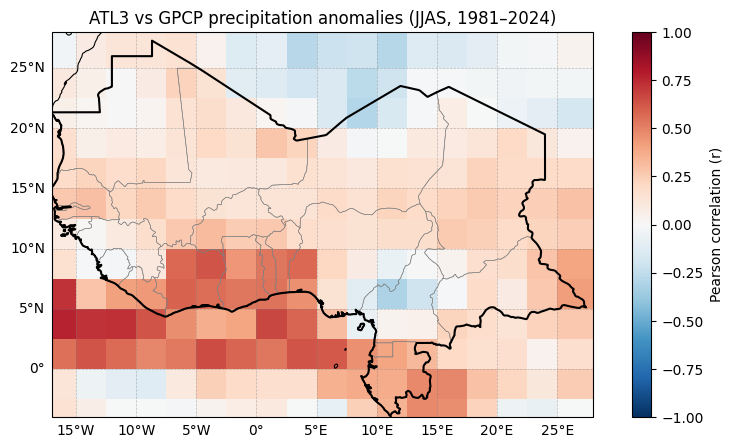

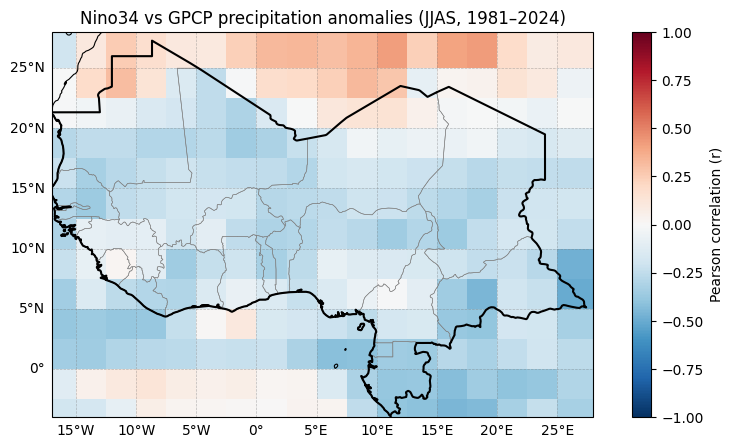

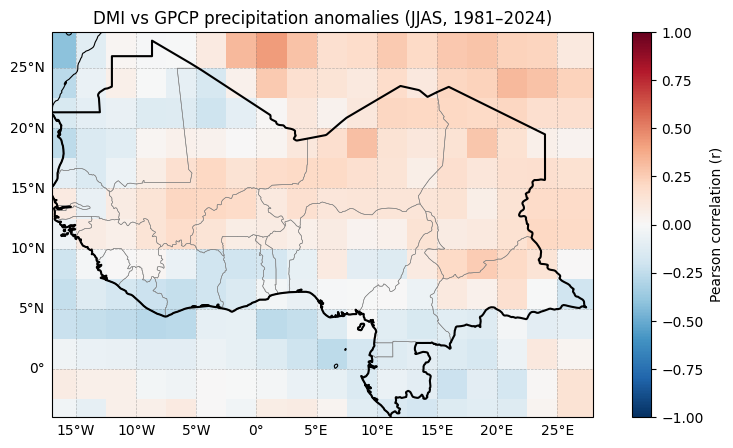

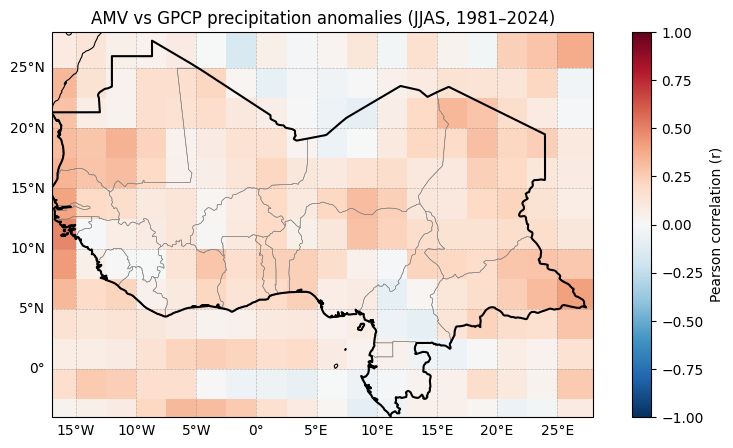

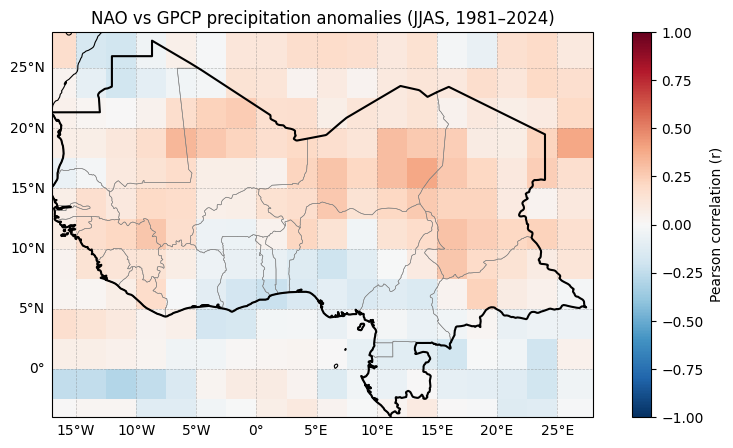

In [ ]:
# Plot GPCP JJAS correlation maps

save_dir = "/content/drive/MyDrive/TESI/Correlation_maps/GPCP"
os.makedirs(save_dir, exist_ok=True)

for index_name, correlation in gpcp_correlations_jjas.items():

    fig = plt.figure(figsize=(10, 5))
    ax = plt.axes(projection=ccrs.PlateCarree())

    # GPCP grid coordinates
    lon = correlation.lon.values
    lat = correlation.lat.values

    # Calculate cell boundaries
    lon_edges = np.empty(len(lon) + 1)
    lat_edges = np.empty(len(lat) + 1)

    lon_edges[1:-1] = (lon[:-1] + lon[1:]) / 2
    lat_edges[1:-1] = (lat[:-1] + lat[1:]) / 2

    # Match longitude boundaries to the common domain
    if lon[0] < lon[-1]:
        lon_edges[0] = lon_regions[0]
        lon_edges[-1] = lon_regions[1]
    else:
        lon_edges[0] = lon_regions[1]
        lon_edges[-1] = lon_regions[0]

    # Match latitude boundaries to the common domain
    south = lat_regions[1]
    north = lat_regions[0]

    if lat[0] < lat[-1]:
        lat_edges[0] = south
        lat_edges[-1] = north
    else:
        lat_edges[0] = north
        lat_edges[-1] = south

    # Plot correlation map
    im = ax.pcolormesh(
        lon_edges,
        lat_edges,
        correlation.values,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        shading="flat"
    )

    # Colorbar
    fig.colorbar(
        im,
        ax=ax,
        label="Pearson correlation (r)"
    )

    # Internal country boundaries
    ax.add_geometries(
        wa.geometry,
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="gray",
        linewidth=0.4,
        zorder=3
    )

    # External West Africa boundary
    ax.add_geometries(
        wa_outline.geometry,
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="black",
        linewidth=1.5,
        zorder=4
    )

    ax.coastlines(resolution="50m", linewidth=0.8, zorder=3)

    # West Africa domain
    ax.set_extent(
        [lon_regions[0], lon_regions[1],
         lat_regions[1], lat_regions[0]],
        crs=ccrs.PlateCarree()
    )

    # Latitude and longitude labels
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=0.5,
        color="gray",
        alpha=0.5,
        linestyle="--"
    )

    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.MultipleLocator(5)
    gl.ylocator = mticker.MultipleLocator(5)

    ax.set_title(
        f"{index_name} vs GPCP precipitation anomalies (JJAS, 1981–2024)"
    )

    filename = f"{index_name}_GPCP_JJAS_correlation.png"

    plt.savefig(
        os.path.join(save_dir, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# Seasonal Pearson correlations: climate indices vs CHIRPS JJAS precipitation anomalies


/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


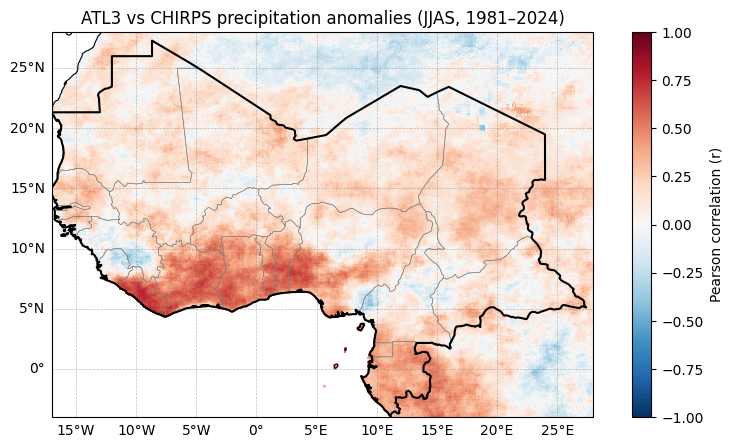

/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


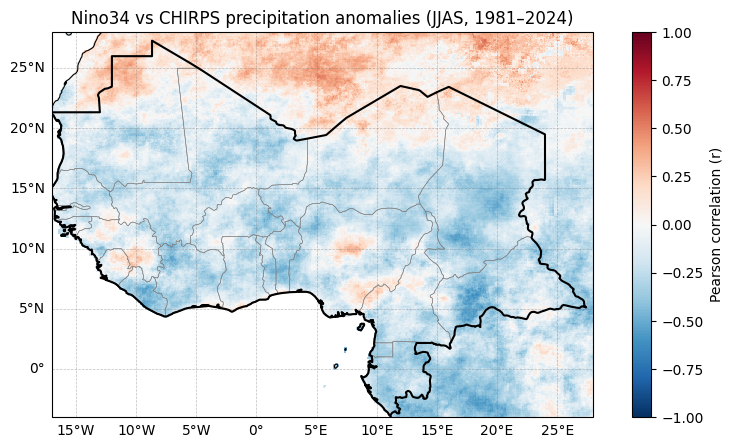

/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


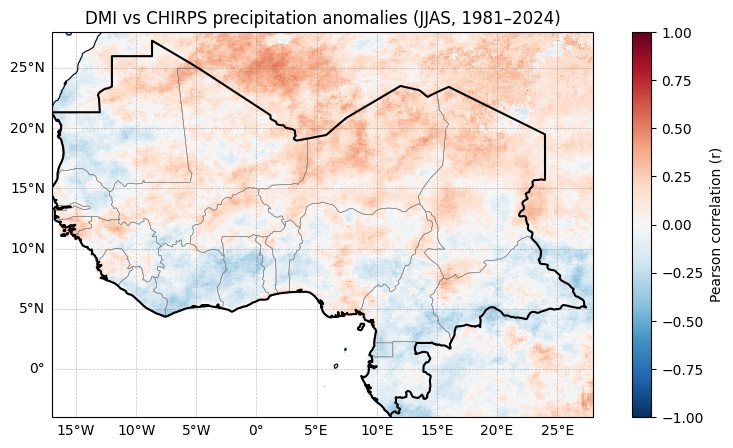

/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


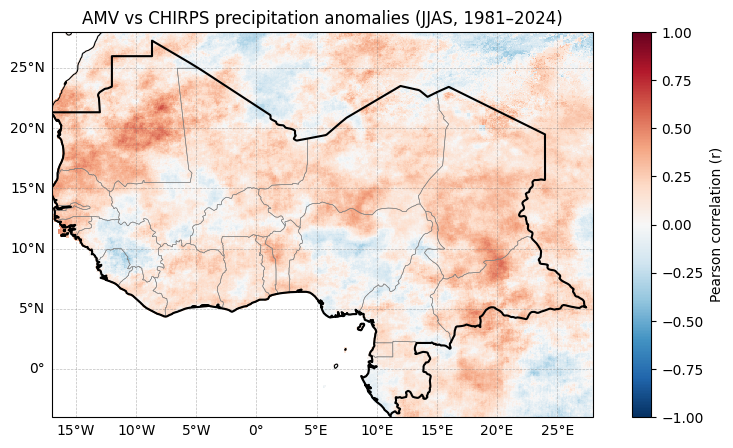

/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


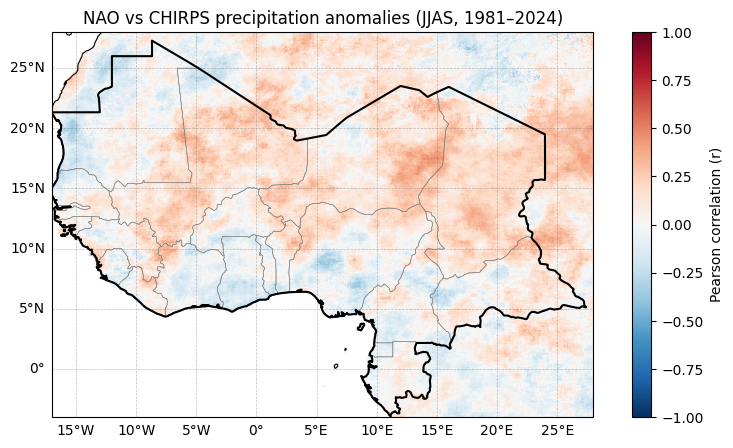

In [ ]:
# Plot CHIRPS JJAS correlation maps

save_dir = "/content/drive/MyDrive/TESI/Correlation_maps/CHIRPS"
os.makedirs(save_dir, exist_ok=True)

for index_name, correlation in chirps_correlations_jjas.items():

    fig = plt.figure(figsize=(10, 5))
    ax = plt.axes(projection=ccrs.PlateCarree())

    correlation.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        cbar_kwargs={"label": "Pearson correlation (r)"}
    )

    # Internal country boundaries
    ax.add_geometries(
        wa.geometry,
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="gray",
        linewidth=0.4,
        zorder=3
    )

    # External West Africa boundary
    ax.add_geometries(
        wa_outline.geometry,
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="black",
        linewidth=1.5,
        zorder=4
    )

    ax.coastlines(resolution="50m", linewidth=0.8, zorder=3)

    # West Africa domain
    ax.set_extent(
        [lon_regions[0], lon_regions[1],
         lat_regions[1], lat_regions[0]],
        crs=ccrs.PlateCarree()
    )

    # Latitude and longitude labels
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=0.5,
        color="gray",
        alpha=0.5,
        linestyle="--"
    )

    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.MultipleLocator(5)
    gl.ylocator = mticker.MultipleLocator(5)

    ax.set_title(
        f"{index_name} vs CHIRPS precipitation anomalies (JJAS, 1981–2024)"
    )

    # Save figure
    filename = f"{index_name}_CHIRPS_JJAS_correlation.png"

    plt.savefig(
        os.path.join(save_dir, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


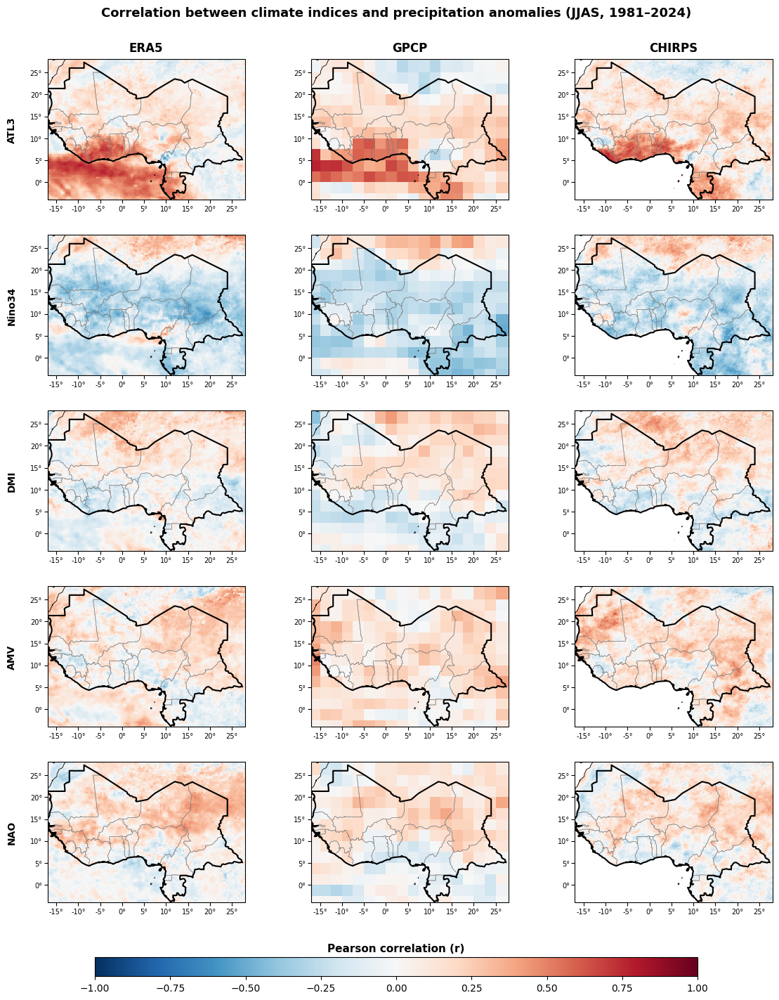

In [ ]:
# Combined correlation maps: ERA5, GPCP and CHIRPS

datasets = {
    "ERA5": era5_correlations_jjas,
    "GPCP": gpcp_correlations_jjas,
    "CHIRPS": chirps_correlations_jjas
}

indices_names = ["ATL3", "Nino34", "DMI", "AMV", "NAO"]

fig, axes = plt.subplots(
    nrows=5,
    ncols=3,
    figsize=(13, 15),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

for row, index_name in enumerate(indices_names):
    for col, (dataset_name, correlations) in enumerate(datasets.items()):

        ax = axes[row, col]
        correlation = correlations[index_name]

        # Remove auxiliary number coordinate
        if "number" in correlation.coords:
            correlation = correlation.reset_coords("number", drop=True)

        # Select coordinate names
        if "longitude" in correlation.dims:
            x_dim, y_dim = "longitude", "latitude"
        else:
            x_dim, y_dim = "lon", "lat"

        # GPCP: adjust outer grid-cell boundaries
        if dataset_name == "GPCP":

            lon = correlation[x_dim].values
            lat = correlation[y_dim].values

            lon_edges = np.empty(len(lon) + 1)
            lat_edges = np.empty(len(lat) + 1)

            lon_edges[1:-1] = (lon[:-1] + lon[1:]) / 2
            lat_edges[1:-1] = (lat[:-1] + lat[1:]) / 2

            if lon[0] < lon[-1]:
                lon_edges[0] = lon_regions[0]
                lon_edges[-1] = lon_regions[1]
            else:
                lon_edges[0] = lon_regions[1]
                lon_edges[-1] = lon_regions[0]

            if lat[0] < lat[-1]:
                lat_edges[0] = lat_regions[1]
                lat_edges[-1] = lat_regions[0]
            else:
                lat_edges[0] = lat_regions[0]
                lat_edges[-1] = lat_regions[1]

            im = ax.pcolormesh(
                lon_edges,
                lat_edges,
                correlation.values,
                transform=ccrs.PlateCarree(),
                cmap="RdBu_r",
                vmin=-1,
                vmax=1,
                shading="flat"
            )

        else:

            im = correlation.plot.pcolormesh(
                x=x_dim,
                y=y_dim,
                ax=ax,
                transform=ccrs.PlateCarree(),
                cmap="RdBu_r",
                vmin=-1,
                vmax=1,
                add_colorbar=False
            )

        # Internal country boundaries
        ax.add_geometries(
            wa.geometry,
            crs=ccrs.PlateCarree(),
            facecolor="none",
            edgecolor="gray",
            linewidth=0.4,
            zorder=3
        )

        # External West Africa boundary
        ax.add_geometries(
            wa_outline.geometry,
            crs=ccrs.PlateCarree(),
            facecolor="none",
            edgecolor="black",
            linewidth=1.5,
            zorder=4
        )

        ax.coastlines(resolution="50m", linewidth=0.6, zorder=3)

        # West Africa domain
        ax.set_extent(
            [lon_regions[0], lon_regions[1],
             lat_regions[1], lat_regions[0]],
            crs=ccrs.PlateCarree()
        )

        # Coordinate ticks
        ax.set_xticks(np.arange(-15, 28, 5), crs=ccrs.PlateCarree())
        ax.set_yticks(np.arange(0, 28, 5), crs=ccrs.PlateCarree())

        ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%d°"))
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%d°"))

        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(labelsize=7, pad=2)

        # Dataset titles
        if row == 0:
            ax.set_title(dataset_name, fontsize=12, fontweight="bold", pad=8)

        # Index labels
        if col == 0:
            ax.text(
                -0.18, 0.5, index_name,
                transform=ax.transAxes,
                rotation=90,
                va="center",
                ha="center",
                fontsize=10,
                fontweight="bold",
                clip_on=False
            )

# Shared colorbar
cbar_ax = fig.add_axes([0.17, 0.05, 0.66, 0.018])

cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.ax.set_title(
    "Pearson correlation (r)",
    fontsize=11,
    pad=6,
    fontweight="bold"
)

fig.suptitle(
    "Correlation between climate indices and precipitation anomalies (JJAS, 1981–2024)",
    fontsize=13,
    fontweight="bold",
    y=0.97
)

# Adjust spacing
fig.subplots_adjust(
    left=0.09,
    right=0.94,
    top=0.92,
    bottom=0.12,
    hspace=0.25,
    wspace=0.06
)

# Save figure
save_dir = "/content/drive/MyDrive/TESI/Correlation_maps"
os.makedirs(save_dir, exist_ok=True)

filename = "Correlation_maps_JJAS_1981-2024.png"

plt.savefig(
    os.path.join(save_dir, filename),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

## Compute monthly mean anomaly correlation



In [ ]:
# Monthly precipitation anomalies (JJAS)

def calculate_monthly_anomalies(pr):

    climatology = pr.sel(
        time=slice("1981-01-01", "2014-12-31")
    ).groupby("time.month").mean("time")

    anomalies = pr.groupby("time.month") - climatology

    return anomalies.sel(time=anomalies.time.dt.month.isin([6, 7, 8, 9]))

era5_anomalies_monthly = calculate_monthly_anomalies(pr_era5)
gpcp_anomalies_monthly = calculate_monthly_anomalies(pr_gpcp)
chirps_anomalies_monthly = calculate_monthly_anomalies(pr_chirps)

In [ ]:
# Monthly correlations: climate indices vs precipitation anomalies

months = {
    "June": 6,
    "July": 7,
    "August": 8,
    "September": 9
}

datasets = {
    "ERA5": era5_anomalies_monthly,
    "GPCP": gpcp_anomalies_monthly,
    "CHIRPS": chirps_anomalies_monthly
}

monthly_correlations = {}

for index_name, index in indices.items():

    monthly_correlations[index_name] = {}

    for month_name, month_number in months.items():

        index_month = index.where(
            index.valid_time.dt.month == month_number,
            drop=True
        )

        monthly_correlations[index_name][month_name] = {}

        for dataset_name, precipitation in datasets.items():

            precip_month = precipitation.where(
                precipitation.time.dt.month == month_number,
                drop=True
            )

            # Align time coordinates
            index_aligned, precip_aligned = xr.align(
                index_month,
                precip_month,
                join="inner"
            )

            # Rename time coordinate if necessary
            if "valid_time" in index_aligned.dims:
                index_aligned = index_aligned.rename(
                    {"valid_time": "time"}
                )

            # Calculate Pearson correlation
            monthly_correlations[index_name][month_name][dataset_name] = xr.corr(
                index_aligned,
                precip_aligned,
                dim="time"
            )

In [ ]:
for index_name in monthly_correlations:
    for month_name in monthly_correlations[index_name]:
        for dataset_name, correlation in monthly_correlations[index_name][month_name].items():
            print(index_name, month_name, dataset_name, correlation.dims, correlation.shape)

ATL3 June ERA5 ('latitude', 'longitude') (129, 181)
ATL3 June GPCP ('lat', 'lon') (13, 18)
ATL3 June CHIRPS ('latitude', 'longitude') (640, 900)
ATL3 July ERA5 ('latitude', 'longitude') (129, 181)
ATL3 July GPCP ('lat', 'lon') (13, 18)
ATL3 July CHIRPS ('latitude', 'longitude') (640, 900)
ATL3 August ERA5 ('latitude', 'longitude') (129, 181)
ATL3 August GPCP ('lat', 'lon') (13, 18)
ATL3 August CHIRPS ('latitude', 'longitude') (640, 900)
ATL3 September ERA5 ('latitude', 'longitude') (129, 181)
ATL3 September GPCP ('lat', 'lon') (13, 18)
ATL3 September CHIRPS ('latitude', 'longitude') (640, 900)
Nino34 June ERA5 ('latitude', 'longitude') (129, 181)
Nino34 June GPCP ('lat', 'lon') (13, 18)
Nino34 June CHIRPS ('latitude', 'longitude') (640, 900)
Nino34 July ERA5 ('latitude', 'longitude') (129, 181)
Nino34 July GPCP ('lat', 'lon') (13, 18)
Nino34 July CHIRPS ('latitude', 'longitude') (640, 900)
Nino34 August ERA5 ('latitude', 'longitude') (129, 181)
Nino34 August GPCP ('lat', 'lon') (13, 18

/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value enc

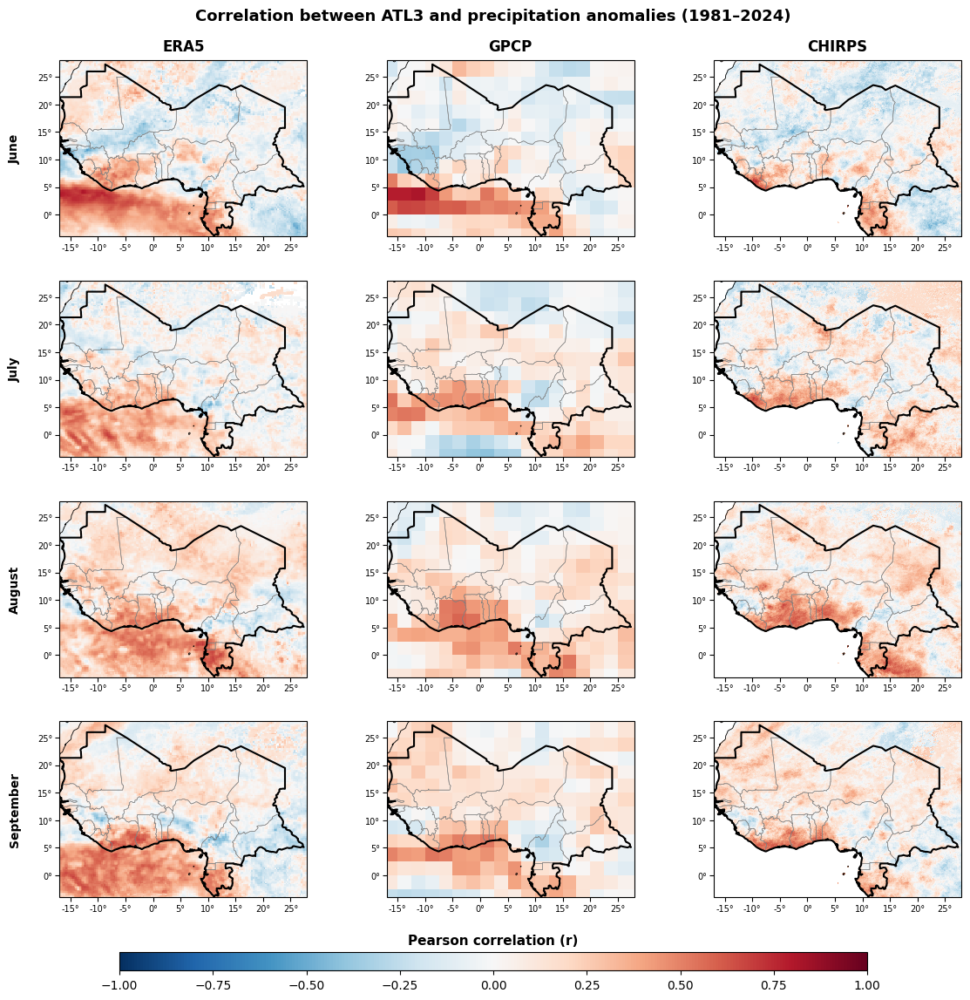

/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value enc

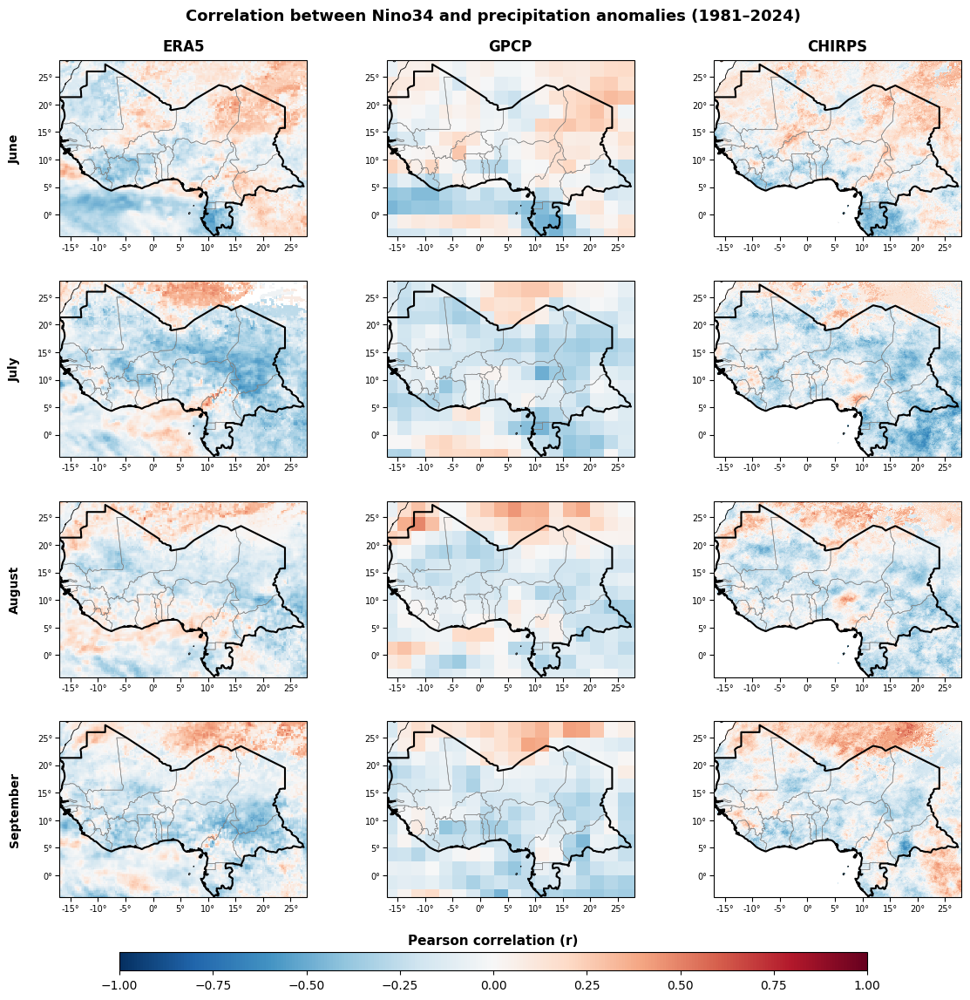

/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value enc

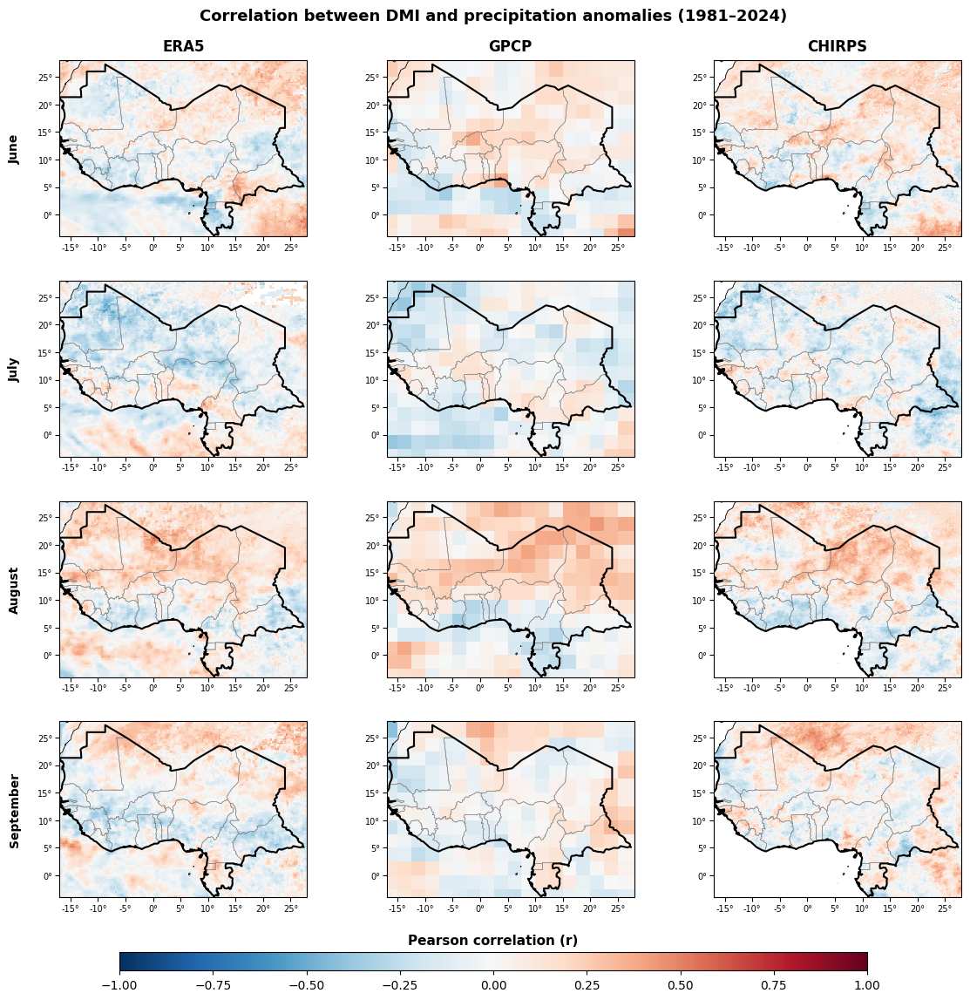

/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value enc

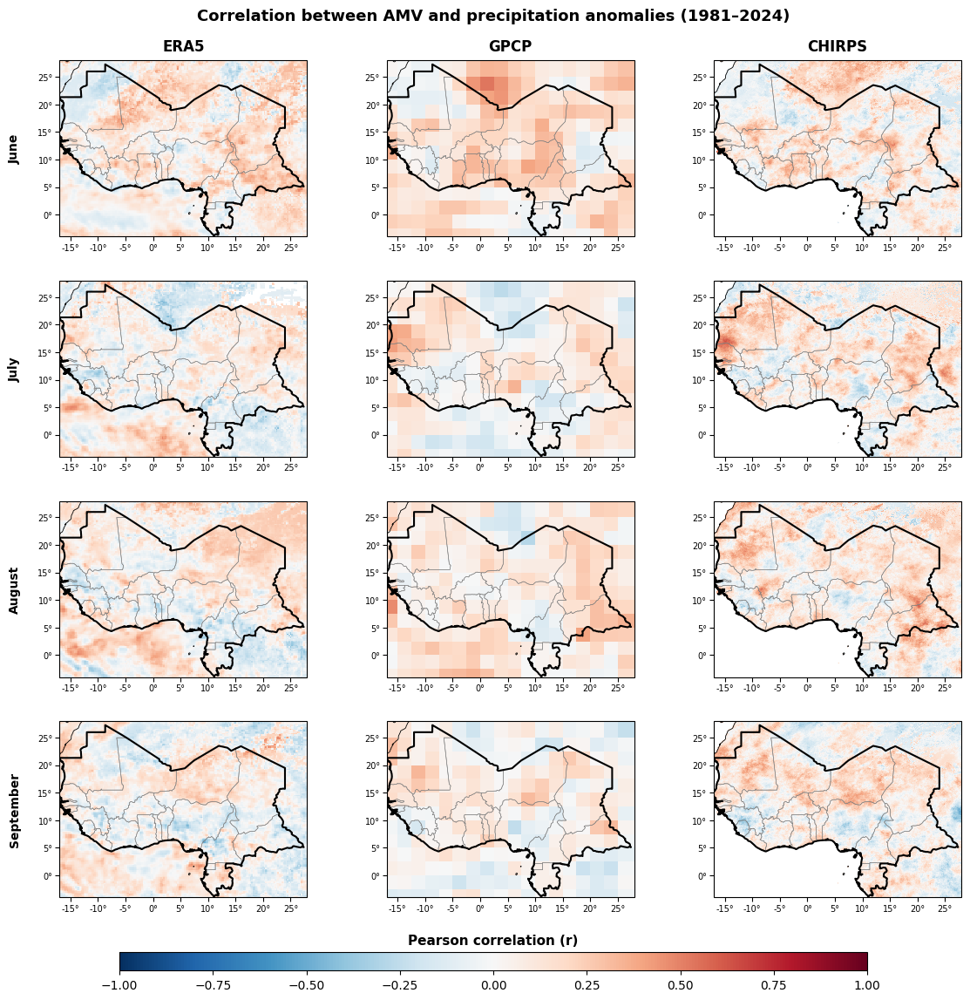

/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/usr/local/lib/python3.13/dist-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value enc

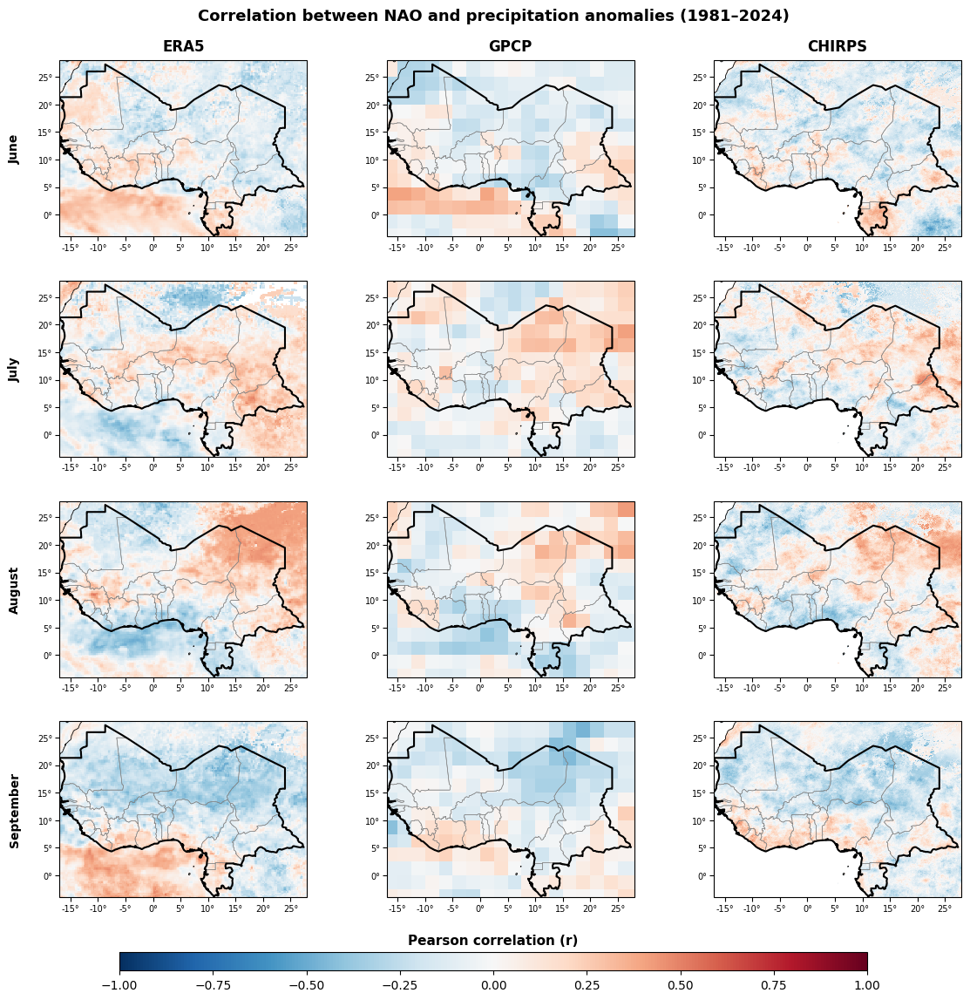

In [ ]:

# Monthly correlation maps: ERA5, GPCP and CHIRPS

datasets = {
    "ERA5": "ERA5",
    "GPCP": "GPCP",
    "CHIRPS": "CHIRPS"
}

indices_names = ["ATL3", "Nino34", "DMI", "AMV", "NAO"]

months = ["June", "July", "August", "September"]

for index_name in indices_names:

    fig, axes = plt.subplots(
        nrows=4,
        ncols=3,
        figsize=(13, 12),
        subplot_kw={"projection": ccrs.PlateCarree()}
    )

    for row, month_name in enumerate(months):
        for col, dataset_name in enumerate(datasets):

            ax = axes[row, col]

            correlation = monthly_correlations[index_name][month_name][dataset_name]

            # Remove auxiliary number coordinate
            if "number" in correlation.coords:
                correlation = correlation.reset_coords("number", drop=True)

            # Select coordinate names
            if "longitude" in correlation.dims:
                x_dim, y_dim = "longitude", "latitude"
            else:
                x_dim, y_dim = "lon", "lat"

            # GPCP: adjust outer grid-cell boundaries
            if dataset_name == "GPCP":

                lon = correlation[x_dim].values
                lat = correlation[y_dim].values

                lon_edges = np.empty(len(lon) + 1)
                lat_edges = np.empty(len(lat) + 1)

                lon_edges[1:-1] = (lon[:-1] + lon[1:]) / 2
                lat_edges[1:-1] = (lat[:-1] + lat[1:]) / 2

                if lon[0] < lon[-1]:
                    lon_edges[0] = lon_regions[0]
                    lon_edges[-1] = lon_regions[1]
                else:
                    lon_edges[0] = lon_regions[1]
                    lon_edges[-1] = lon_regions[0]

                if lat[0] < lat[-1]:
                    lat_edges[0] = lat_regions[1]
                    lat_edges[-1] = lat_regions[0]
                else:
                    lat_edges[0] = lat_regions[0]
                    lat_edges[-1] = lat_regions[1]

                im = ax.pcolormesh(
                    lon_edges,
                    lat_edges,
                    correlation.values,
                    transform=ccrs.PlateCarree(),
                    cmap="RdBu_r",
                    vmin=-1,
                    vmax=1,
                    shading="flat"
                )

            else:

                im = correlation.plot.pcolormesh(
                    x=x_dim,
                    y=y_dim,
                    ax=ax,
                    transform=ccrs.PlateCarree(),
                    cmap="RdBu_r",
                    vmin=-1,
                    vmax=1,
                    add_colorbar=False
                )

            # Internal country boundaries
            ax.add_geometries(
                wa.geometry,
                crs=ccrs.PlateCarree(),
                facecolor="none",
                edgecolor="gray",
                linewidth=0.4,
                zorder=3
            )

            # External West Africa boundary
            ax.add_geometries(
                wa_outline.geometry,
                crs=ccrs.PlateCarree(),
                facecolor="none",
                edgecolor="black",
                linewidth=1.5,
                zorder=4
            )

            ax.coastlines(resolution="50m", linewidth=0.6, zorder=3)

            # West Africa domain
            ax.set_extent(
                [lon_regions[0], lon_regions[1],
                 lat_regions[1], lat_regions[0]],
                crs=ccrs.PlateCarree()
            )

            # Coordinate ticks
            ax.set_xticks(np.arange(-15, 28, 5), crs=ccrs.PlateCarree())
            ax.set_yticks(np.arange(0, 28, 5), crs=ccrs.PlateCarree())

            ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%d°"))
            ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%d°"))

            ax.set_xlabel("")
            ax.set_ylabel("")
            ax.tick_params(labelsize=7, pad=2)

            # Dataset titles
            if row == 0:
                ax.set_title(dataset_name, fontsize=12, fontweight="bold", pad=8)

            # Month labels
            if col == 0:
                ax.text(
                    -0.18, 0.5, month_name,
                    transform=ax.transAxes,
                    rotation=90,
                    va="center",
                    ha="center",
                    fontsize=10,
                    fontweight="bold",
                    clip_on=False
                )

    # Shared colorbar
    cbar_ax = fig.add_axes([0.17, 0.05, 0.66, 0.018])

    cbar = fig.colorbar(
        im,
        cax=cbar_ax,
        orientation="horizontal"
    )

    cbar.ax.set_title(
        "Pearson correlation (r)",
        fontsize=11,
        pad=6,
        fontweight="bold"
    )

    fig.suptitle(
        f"Correlation between {index_name} and precipitation anomalies (1981–2024)",
        fontsize=13,
        fontweight="bold",
        y=0.97
    )

    # Adjust spacing
    fig.subplots_adjust(
        left=0.09,
        right=0.94,
        top=0.92,
        bottom=0.12,
        hspace=0.25,
        wspace=0.06
    )

    # Save figure
    save_dir = "/content/drive/MyDrive/TESI/Correlation_maps/Monthly_correlation"
    os.makedirs(save_dir, exist_ok=True)

    filename = f"Correlation_maps_{index_name}_monthly_1981-2024.png"

    plt.savefig(
        os.path.join(save_dir, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# Partial correlation

In [ ]:
def partial_corr(x, y, z1, z2):

    valid = np.isfinite(x) & np.isfinite(y) & np.isfinite(z1) & np.isfinite(z2)

    if valid.sum() < 5:
        return np.nan

    x = x[valid]
    y = y[valid]
    z1 = z1[valid]
    z2 = z2[valid]

    Z = np.column_stack([
        np.ones(len(z1)),
        z1,
        z2
    ])

    x_res = x - Z @ np.linalg.lstsq(Z, x, rcond=None)[0]
    y_res = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]

    return np.corrcoef(x_res, y_res)[0, 1]

In [ ]:
def calculate_partial_correlation(index_name, precipitation, indices):

    control_names = [
        name for name in ["ATL3", "Nino34", "DMI"]
        if name != index_name
    ]

    precipitation = precipitation.chunk({"year": -1})

    partial_correlation = xr.apply_ufunc(
        partial_corr,
        indices[index_name],
        precipitation,
        indices[control_names[0]],
        indices[control_names[1]],
        input_core_dims=[
            ["year"], ["year"], ["year"], ["year"]
        ],
        output_core_dims=[[]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )

    return partial_correlation

In [ ]:
# Precipitation datasets
precipitation_datasets = {
    "ERA5": pr_era5_anom_jjas,
    "GPCP": pr_gpcp_anom_jjas,
    "CHIRPS": pr_chirps_anom_jjas
}

indices_names = ["ATL3", "Nino34", "DMI"]

partial_correlations = {}

for dataset_name, precipitation in precipitation_datasets.items():

    partial_correlations[dataset_name] = {}

    for index_name in indices_names:

        partial_correlations[dataset_name][index_name] = (
            calculate_partial_correlation(
                index_name,
                precipitation,
                indices_jjas
            )
        )

        print(
            f"{dataset_name} - {index_name}: "
            f"{partial_correlations[dataset_name][index_name].shape}"
        )

ERA5 - ATL3: (129, 181)
ERA5 - Nino34: (129, 181)
ERA5 - DMI: (129, 181)
GPCP - ATL3: (13, 18)
GPCP - Nino34: (13, 18)
GPCP - DMI: (13, 18)
CHIRPS - ATL3: (640, 900)
CHIRPS - Nino34: (640, 900)
CHIRPS - DMI: (640, 900)


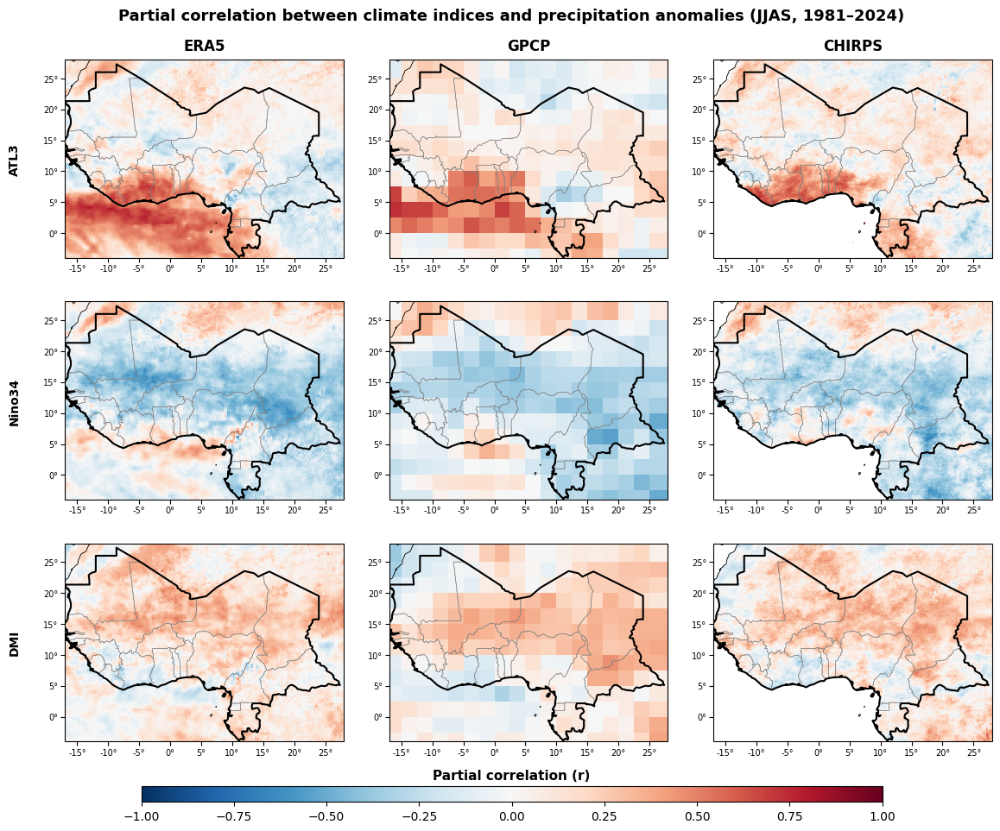

In [ ]:
# Combined partial correlation maps

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(13, 10),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

for row, index_name in enumerate(indices_names):
    for col, (dataset_name, correlations) in enumerate(partial_correlations.items()):

        ax = axes[row, col]
        correlation = correlations[index_name]

        # Remove auxiliary ERA5 coordinate if present
        if "number" in correlation.coords:
            correlation = correlation.reset_coords("number", drop=True)

        # Identify coordinate names
        if "longitude" in correlation.dims:
            x_dim, y_dim = "longitude", "latitude"
        else:
            x_dim, y_dim = "lon", "lat"

        # Plot GPCP with adjusted grid edges
        if dataset_name == "GPCP":

            lon = correlation[x_dim].values
            lat = correlation[y_dim].values

            lon_edges = np.concatenate([
                [lon_regions[0]],
                (lon[:-1] + lon[1:]) / 2,
                [lon_regions[1]]
            ])

            lat_edges = np.concatenate([
                [lat_regions[1]],
                (lat[:-1] + lat[1:]) / 2,
                [lat_regions[0]]
            ])

            im = ax.pcolormesh(
                lon_edges,
                lat_edges,
                correlation.values,
                transform=ccrs.PlateCarree(),
                cmap="RdBu_r",
                vmin=-1,
                vmax=1,
                shading="flat"
            )

        else:
            im = correlation.plot.pcolormesh(
                x=x_dim,
                y=y_dim,
                ax=ax,
                transform=ccrs.PlateCarree(),
                cmap="RdBu_r",
                vmin=-1,
                vmax=1,
                add_colorbar=False
            )

        # Internal country boundaries
        ax.add_geometries(
            wa.geometry,
            crs=ccrs.PlateCarree(),
            facecolor="none",
            edgecolor="gray",
            linewidth=0.4,
            zorder=3
        )

        # External West Africa boundary
        ax.add_geometries(
            wa_outline.geometry,
            crs=ccrs.PlateCarree(),
            facecolor="none",
            edgecolor="black",
            linewidth=1.5,
            zorder=4
        )

        ax.coastlines(resolution="50m", linewidth=0.6, zorder=3)

        # West Africa domain
        ax.set_extent(
            [lon_regions[0], lon_regions[1],
             lat_regions[1], lat_regions[0]],
            crs=ccrs.PlateCarree()
        )

        # Coordinate ticks
        ax.set_xticks(np.arange(-15, 28, 5), crs=ccrs.PlateCarree())
        ax.set_yticks(np.arange(0, 28, 5), crs=ccrs.PlateCarree())

        ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%d°"))
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%d°"))

        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(labelsize=7, pad=2)

        # Dataset titles
        if row == 0:
            ax.set_title(dataset_name, fontsize=12, fontweight="bold", pad=8)

        # Index labels
        if col == 0:
            ax.text(
                -0.18, 0.5, index_name,
                transform=ax.transAxes,
                rotation=90,
                va="center",
                ha="center",
                fontsize=10,
                fontweight="bold",
                clip_on=False
            )

# Shared colorbar
cbar_ax = fig.add_axes([0.17, 0.05, 0.66, 0.018])

cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.ax.set_title(
    "Partial correlation (r)",
    fontsize=11,
    pad=6,
    fontweight="bold"
)

fig.suptitle(
    "Partial correlation between climate indices and precipitation anomalies (JJAS, 1981–2024)",
    fontsize=13,
    fontweight="bold",
    y=0.97
)

# Adjust spacing
fig.subplots_adjust(
    left=0.09,
    right=0.94,
    top=0.91,
    bottom=0.12,
    hspace=0.22,
    wspace=0.06
)

# Save figure
save_dir = "/content/drive/MyDrive/TESI/Correlation_maps/Partial_Correlation"
os.makedirs(save_dir, exist_ok=True)

filename = "Partial_correlation_maps_JJAS_1981-2024.png"

plt.savefig(
    os.path.join(save_dir, filename),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Partial correlation for all indices

In [ ]:
def partial_corr(x, y, *controls):

    valid = np.isfinite(x) & np.isfinite(y)

    for z in controls:
        valid &= np.isfinite(z)

    if valid.sum() < 5:
        return np.nan

    x = x[valid]
    y = y[valid]
    controls = [z[valid] for z in controls]

    Z = np.column_stack([
        np.ones(len(x)),
        *controls
    ])

    x_res = x - Z @ np.linalg.lstsq(Z, x, rcond=None)[0]
    y_res = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]

    return np.corrcoef(x_res, y_res)[0, 1]

In [ ]:
def calculate_partial_correlation(index_name, precipitation, indices):

    control_names = [
        name for name in ["ATL3", "Nino34", "DMI", "NAO", "AMV"]
        if name != index_name
    ]

    precipitation = precipitation.chunk({"year": -1})

    partial_correlation = xr.apply_ufunc(
        partial_corr,
        indices[index_name],
        precipitation,
        *[indices[name] for name in control_names],
        input_core_dims=[["year"]] * 6,
        output_core_dims=[[]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )

    return partial_correlation

In [ ]:
# Precipitation datasets
precipitation_datasets = {
    "ERA5": pr_era5_anom_jjas,
    "GPCP": pr_gpcp_anom_jjas,
    "CHIRPS": pr_chirps_anom_jjas
}

indices_names = ["ATL3", "Nino34", "DMI", "NAO", "AMV"]

partial_correlations = {}

for dataset_name, precipitation in precipitation_datasets.items():

    partial_correlations[dataset_name] = {}

    for index_name in indices_names:

        partial_correlations[dataset_name][index_name] = (
            calculate_partial_correlation(
                index_name,
                precipitation,
                indices_jjas
            )
        )

        print(
            f"{dataset_name} - {index_name}: "
            f"{partial_correlations[dataset_name][index_name].shape}"
        )

ERA5 - ATL3: (129, 181)
ERA5 - Nino34: (129, 181)
ERA5 - DMI: (129, 181)
ERA5 - NAO: (129, 181)
ERA5 - AMV: (129, 181)
GPCP - ATL3: (13, 18)
GPCP - Nino34: (13, 18)
GPCP - DMI: (13, 18)
GPCP - NAO: (13, 18)
GPCP - AMV: (13, 18)
CHIRPS - ATL3: (640, 900)
CHIRPS - Nino34: (640, 900)
CHIRPS - DMI: (640, 900)
CHIRPS - NAO: (640, 900)
CHIRPS - AMV: (640, 900)


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


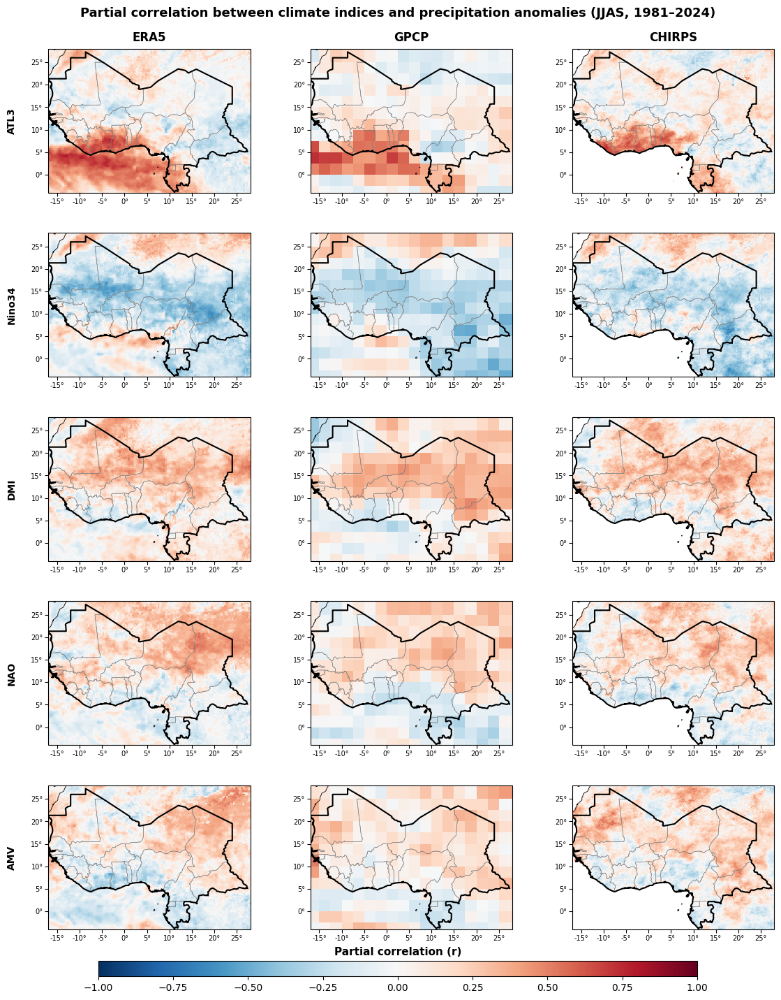

In [ ]:
# Indices to analyse
indices_names = ["ATL3", "Nino34", "DMI", "NAO", "AMV"]

# Combined partial correlation maps

fig, axes = plt.subplots(
    nrows=5,
    ncols=3,
    figsize=(13, 15),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

for row, index_name in enumerate(indices_names):
    for col, (dataset_name, correlations) in enumerate(partial_correlations.items()):

        ax = axes[row, col]
        correlation = correlations[index_name]

        # Remove auxiliary ERA5 coordinate if present
        if "number" in correlation.coords:
            correlation = correlation.reset_coords("number", drop=True)

        # Identify coordinate names
        if "longitude" in correlation.dims:
            x_dim, y_dim = "longitude", "latitude"
        else:
            x_dim, y_dim = "lon", "lat"

        # Plot GPCP with adjusted grid edges
        if dataset_name == "GPCP":

            lon = correlation[x_dim].values
            lat = correlation[y_dim].values

            lon_edges = np.concatenate([
                [lon_regions[0]],
                (lon[:-1] + lon[1:]) / 2,
                [lon_regions[1]]
            ])

            lat_edges = np.concatenate([
                [lat_regions[1]],
                (lat[:-1] + lat[1:]) / 2,
                [lat_regions[0]]
            ])

            im = ax.pcolormesh(
                lon_edges,
                lat_edges,
                correlation.values,
                transform=ccrs.PlateCarree(),
                cmap="RdBu_r",
                vmin=-1,
                vmax=1,
                shading="flat"
            )

        else:
            im = correlation.plot.pcolormesh(
                x=x_dim,
                y=y_dim,
                ax=ax,
                transform=ccrs.PlateCarree(),
                cmap="RdBu_r",
                vmin=-1,
                vmax=1,
                add_colorbar=False
            )

        # Internal country boundaries
        ax.add_geometries(
            wa.geometry,
            crs=ccrs.PlateCarree(),
            facecolor="none",
            edgecolor="gray",
            linewidth=0.4,
            zorder=3
        )

        # External West Africa boundary
        ax.add_geometries(
            wa_outline.geometry,
            crs=ccrs.PlateCarree(),
            facecolor="none",
            edgecolor="black",
            linewidth=1.5,
            zorder=4
        )

        ax.coastlines(resolution="50m", linewidth=0.6, zorder=3)

        # West Africa domain
        ax.set_extent(
            [lon_regions[0], lon_regions[1],
             lat_regions[1], lat_regions[0]],
            crs=ccrs.PlateCarree()
        )

        # Coordinate ticks
        ax.set_xticks(np.arange(-15, 28, 5), crs=ccrs.PlateCarree())
        ax.set_yticks(np.arange(0, 28, 5), crs=ccrs.PlateCarree())

        ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%d°"))
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%d°"))

        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(labelsize=7, pad=2)

        # Dataset titles
        if row == 0:
            ax.set_title(dataset_name, fontsize=12, fontweight="bold", pad=8)

        # Index labels
        if col == 0:
            ax.text(
                -0.18, 0.5, index_name,
                transform=ax.transAxes,
                rotation=90,
                va="center",
                ha="center",
                fontsize=10,
                fontweight="bold",
                clip_on=False
            )

# Shared colorbar
cbar_ax = fig.add_axes([0.17, 0.045, 0.66, 0.015])

cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.ax.set_title(
    "Partial correlation (r)",
    fontsize=11,
    pad=6,
    fontweight="bold"
)

fig.suptitle(
    "Partial correlation between climate indices and precipitation anomalies (JJAS, 1981–2024)",
    fontsize=13,
    fontweight="bold",
    y=0.97
)

# Adjust spacing
fig.subplots_adjust(
    left=0.09,
    right=0.94,
    top=0.93,
    bottom=0.09,
    hspace=0.28,
    wspace=0.06
)

# Save figure
save_dir = "/content/drive/MyDrive/TESI/Correlation_maps/Partial_Correlation"
os.makedirs(save_dir, exist_ok=True)

filename = "Partial_correlation_maps_JJAS_1981-2024_all_indices.png"

plt.savefig(
    os.path.join(save_dir, filename),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Multiple linear regression

In [67]:
from scipy import stats

# Select the three predictors
predictors = ["ATL3", "Nino34", "DMI"]

# Precipitation datasets
precipitation_datasets = {
    "ERA5": pr_era5_anom_jjas,
    "GPCP": pr_gpcp_anom_jjas,
    "CHIRPS": pr_chirps_anom_jjas
}

# Multiple Linear Regression function
def calculate_mlr(precipitation, indices_jjas):

    # Create predictor Dataset
    indices_ds = xr.Dataset({
        name: indices_jjas[name]
        for name in predictors
    })

    # Align precipitation and indices
    pr, indices_ds = xr.align(
        precipitation,
        indices_ds,
        join="inner"
    )

    # Convert indices into predictor matrix
    X = indices_ds.to_array(dim="predictor").transpose(
        "year", "predictor"
    )

    # Standardize predictors
    X_std = (X - X.mean("year")) / X.std("year")

    # Convert to numpy arrays
    Y = pr.values
    X_array = X_std.values

    # Identify spatial dimensions
    lat_dim = "latitude" if "latitude" in pr.dims else "lat"
    lon_dim = "longitude" if "longitude" in pr.dims else "lon"

    nlat = pr.sizes[lat_dim]
    nlon = pr.sizes[lon_dim]

    # Initialize output arrays
    betas = np.full((3, nlat, nlon), np.nan)
    pvalues = np.full((3, nlat, nlon), np.nan)
    r2_map = np.full((nlat, nlon), np.nan)

    # Spatial regression
    for i in range(nlat):
        for j in range(nlon):

            y = Y[:, i, j]

            valid = np.isfinite(y) & np.all(
                np.isfinite(X_array), axis=1
            )

            y_valid = y[valid]
            x_valid = X_array[valid, :]

            n = len(y_valid)

            if n <= 4:
                continue

            X_design = np.column_stack([
                np.ones(n),
                x_valid
            ])

            if np.linalg.matrix_rank(X_design) < 4:
                continue

            # OLS regression
            beta, _, _, _ = np.linalg.lstsq(
                X_design, y_valid, rcond=None
            )

            # Predictions and residuals
            y_pred = X_design @ beta
            residuals = y_valid - y_pred

            # R-squared
            ss_res = np.sum(residuals**2)
            ss_tot = np.sum(
                (y_valid - np.mean(y_valid))**2
            )

            if ss_tot == 0:
                continue

            r2_map[i, j] = 1 - ss_res / ss_tot

            # Residual variance
            dof = n - 4
            sigma2 = ss_res / dof

            # Coefficient standard errors
            covariance = sigma2 * np.linalg.inv(
                X_design.T @ X_design
            )

            se = np.sqrt(np.diag(covariance))

            # Two-sided p-values
            t_stats = beta[1:] / se[1:]

            pvalues[:, i, j] = 2 * stats.t.sf(
                np.abs(t_stats), dof
            )

            betas[:, i, j] = beta[1:]

    # Create output Dataset
    results = xr.Dataset(
        {
            "beta": (
                ("predictor", lat_dim, lon_dim),
                betas
            ),
            "pvalue": (
                ("predictor", lat_dim, lon_dim),
                pvalues
            ),
            "R2": (
                (lat_dim, lon_dim),
                r2_map
            )
        },
        coords={
            "predictor": predictors,
            lat_dim: pr[lat_dim],
            lon_dim: pr[lon_dim]
        }
    )

    return results


# Calculate MLR for all datasets
mlr_results = {}

for dataset_name, precipitation in precipitation_datasets.items():

    mlr_results[dataset_name] = calculate_mlr(
        precipitation,
        indices_jjas
    )

    print(
        f"{dataset_name}:",
        mlr_results[dataset_name]
    )

ERA5: <xarray.Dataset> Size: 1MB
Dimensions:    (predictor: 3, latitude: 129, longitude: 181)
Coordinates:
  * predictor  (predictor) <U6 72B 'ATL3' 'Nino34' 'DMI'
  * latitude   (latitude) float64 1kB 28.0 27.75 27.5 27.25 ... -3.5 -3.75 -4.0
  * longitude  (longitude) float64 1kB -17.0 -16.75 -16.5 ... 27.5 27.75 28.0
    number     int64 8B 0
Data variables:
    beta       (predictor, latitude, longitude) float64 560kB 0.13 ... 2.02
    pvalue     (predictor, latitude, longitude) float64 560kB 0.8024 ... 0.4717
    R2         (latitude, longitude) float64 187kB 0.05651 0.02924 ... 0.03126
GPCP: <xarray.Dataset> Size: 13kB
Dimensions:    (predictor: 3, lat: 13, lon: 18)
Coordinates:
  * predictor  (predictor) <U6 72B 'ATL3' 'Nino34' 'DMI'
  * lat        (lat) float32 52B -3.75 -1.25 1.25 3.75 ... 21.25 23.75 26.25
  * lon        (lon) float32 72B -16.25 -13.75 -11.25 ... 21.25 23.75 26.25
Data variables:
    beta       (predictor, lat, lon) float64 6kB 0.3354 -0.005121 ... 0.01081
  

In [68]:
for dataset_name, results in mlr_results.items():

    print(f"\n{dataset_name}")
    print("R2 shape:", results["R2"].shape)
    print("Mean R2:", results["R2"].mean().item())

    for index in predictors:
        print(
            index,
            results["beta"].sel(
                predictor=index
            ).mean().item()
        )


ERA5
R2 shape: (129, 181)
Mean R2: 0.15324704053302646
ATL3 2.675302161392169
Nino34 -3.0643648101515906
DMI 1.6659457589648616

GPCP
R2 shape: (13, 18)
Mean R2: 0.15108566330824216
ATL3 2.9945805113614132
Nino34 -3.437163909629676
DMI 1.971498807333785

CHIRPS
R2 shape: (640, 900)
Mean R2: 0.1250865042280988
ATL3 2.4966884664033233
Nino34 -3.6183294921873417
DMI 2.2263529605758148


Common color scale: -33.894 to 33.894


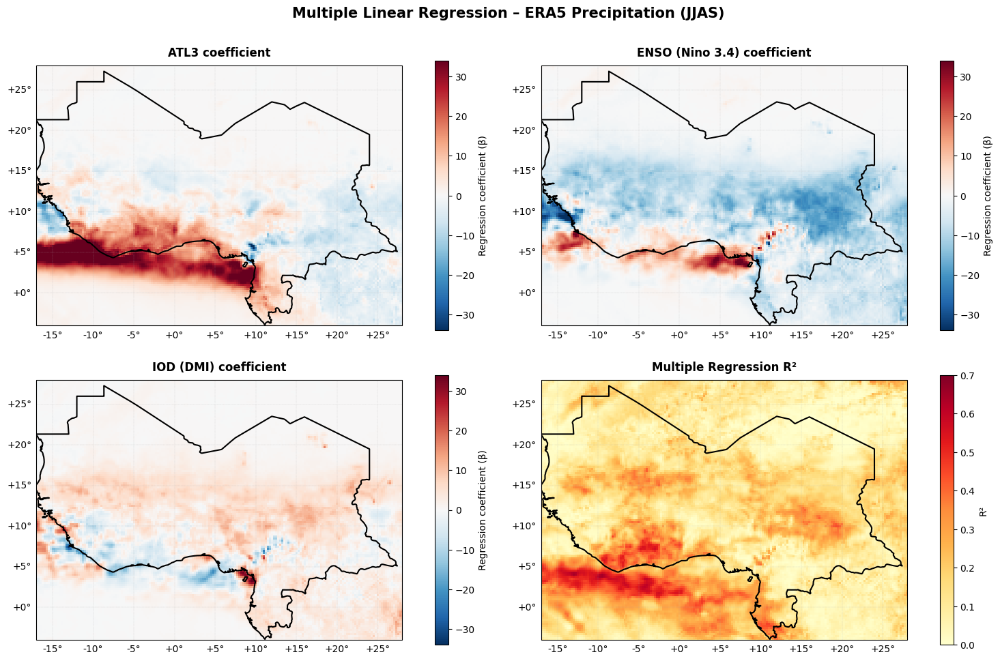

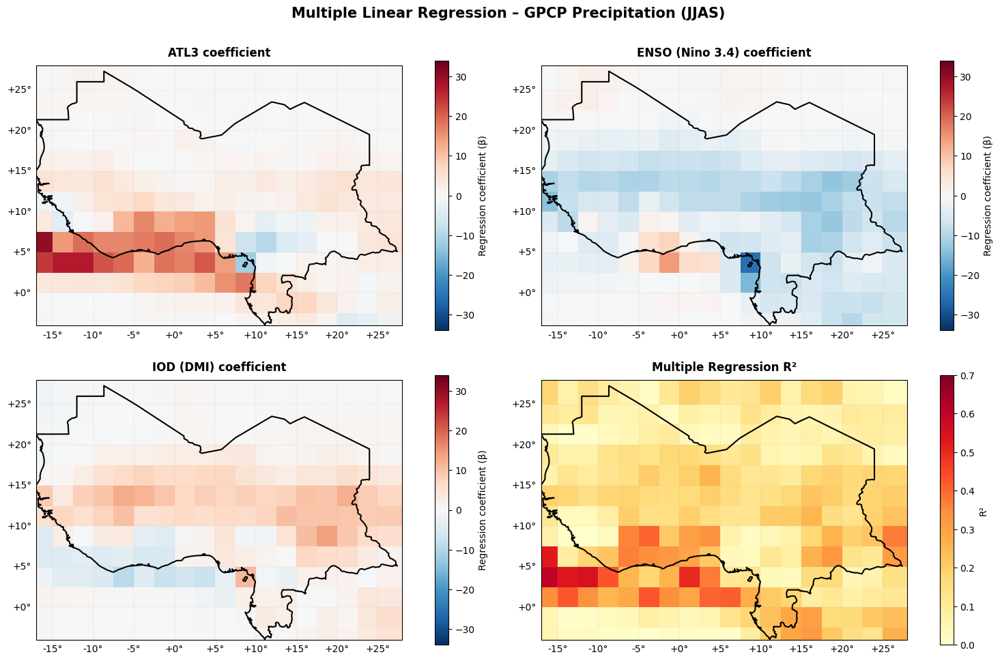

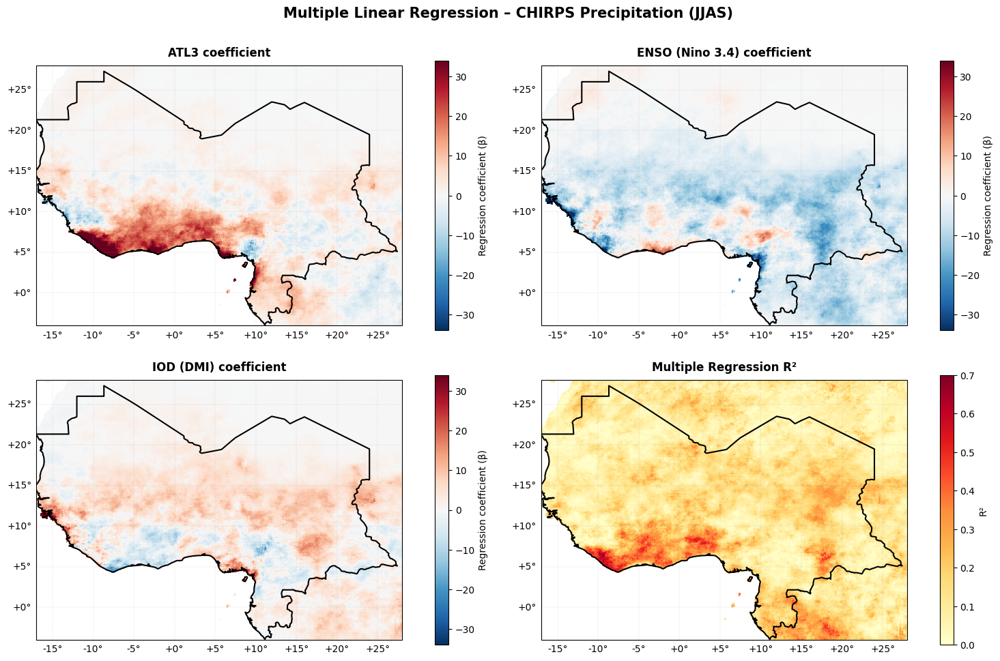

In [69]:
# MLR maps for ERA5, GPCP and CHIRPS

variables = ["ATL3", "Nino34", "DMI", "R2"]

titles = [
    "ATL3 coefficient",
    "ENSO (Nino 3.4) coefficient",
    "IOD (DMI) coefficient",
    "Multiple Regression R²"
]

# Calculate common color limits for ATL3, Nino34 and DMI

predictors = ["ATL3", "Nino34", "DMI"]

percentiles = []

for results in mlr_results.values():

    for predictor in predictors:

        data = results["beta"].sel(predictor=predictor)

        percentiles.append(
            np.nanpercentile(np.abs(data.values), 98)
        )

vmax_common = max(percentiles)

print(f"Common color scale: {-vmax_common:.3f} to {vmax_common:.3f}")


for dataset_name, results in mlr_results.items():

    fig, axes = plt.subplots(
        2, 2,
        figsize=(15, 10),
        subplot_kw={"projection": ccrs.PlateCarree()}
    )

    axes = axes.flatten()

    for ax, var, title in zip(axes, variables, titles):

        if var == "R2":
            data = results["R2"]
            cmap = "YlOrRd"
            vmin, vmax = 0, 0.7

        else:
            data = results["beta"].sel(predictor=var)
            vmin = -vmax_common
            vmax = vmax_common
            cmap = "RdBu_r"

        # Identify coordinate names
        if "longitude" in data.dims:
            lon_dim, lat_dim = "longitude", "latitude"
        else:
            lon_dim, lat_dim = "lon", "lat"

        # Plot GPCP with adjusted grid edges
        if dataset_name == "GPCP":

            lon = data[lon_dim].values
            lat = data[lat_dim].values

            lon_edges = np.concatenate([
                [lon_regions[0]],
                (lon[:-1] + lon[1:]) / 2,
                [lon_regions[1]]
            ])

            lat_edges = np.concatenate([
                [lat_regions[1]],
                (lat[:-1] + lat[1:]) / 2,
                [lat_regions[0]]
            ])

            im = ax.pcolormesh(
                lon_edges,
                lat_edges,
                data.values,
                transform=ccrs.PlateCarree(),
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
                shading="flat"
            )

        else:
            im = ax.pcolormesh(
                data[lon_dim],
                data[lat_dim],
                data,
                transform=ccrs.PlateCarree(),
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
                shading="auto"
            )

        # West Africa external boundary
        ax.add_geometries(
            [wa_union],
            crs=ccrs.PlateCarree(),
            facecolor="none",
            edgecolor="black",
            linewidth=1.5,
            zorder=5
        )

        ax.set_extent(
            [-17, 28, -4, 28],
            crs=ccrs.PlateCarree()
        )

        gl = ax.gridlines(
            draw_labels=True,
            linewidth=0.3,
            alpha=0.5,
            linestyle="--",
            xlocs=np.arange(-15, 28, 5),
            ylocs=np.arange(0, 28, 5)
        )

        gl.top_labels = False
        gl.right_labels = False

        # Signed longitude and latitude labels
        gl.xformatter = FuncFormatter(lambda x, pos: f"{x:+.0f}°")
        gl.yformatter = FuncFormatter(lambda y, pos: f"{y:+.0f}°")

        ax.set_title(title, fontsize=12, fontweight="bold", pad=10)

        cbar = plt.colorbar(
            im,
            ax=ax,
            orientation="vertical",
            pad=0.07,
            shrink=0.87
        )

        if var == "R2":
            cbar.set_label("R²")
        else:
            cbar.set_label("Regression coefficient (β)")

    plt.suptitle(
        f"Multiple Linear Regression – {dataset_name} Precipitation (JJAS)",
        y=0.98,
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.98])

    # Save figure
    save_dir = "/content/drive/MyDrive/TESI/MLR"
    os.makedirs(save_dir, exist_ok=True)

    filename = f"Multiple_Linear_Regression_{dataset_name}_JJAS.png"

    plt.savefig(
        os.path.join(save_dir, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

### MLR for all indices

In [70]:
from scipy import stats

# Select the five predictors
predictors = ["ATL3", "Nino34", "DMI", "NAO", "AMV"]

# Precipitation datasets
precipitation_datasets = {
    "ERA5": pr_era5_anom_jjas,
    "GPCP": pr_gpcp_anom_jjas,
    "CHIRPS": pr_chirps_anom_jjas
}

# Multiple Linear Regression function
def calculate_mlr(precipitation, indices_jjas):

    n_predictors = len(predictors)

    # Create predictor Dataset
    indices_ds = xr.Dataset({
        name: indices_jjas[name]
        for name in predictors
    })

    # Align precipitation and indices
    pr, indices_ds = xr.align(
        precipitation,
        indices_ds,
        join="inner"
    )

    # Convert indices into predictor matrix
    X = indices_ds.to_array(dim="predictor").transpose(
        "year", "predictor"
    )

    # Standardize predictors
    X_std = (X - X.mean("year")) / X.std("year")

    # Convert to numpy arrays
    Y = pr.values
    X_array = X_std.values

    # Identify spatial dimensions
    lat_dim = "latitude" if "latitude" in pr.dims else "lat"
    lon_dim = "longitude" if "longitude" in pr.dims else "lon"

    nlat = pr.sizes[lat_dim]
    nlon = pr.sizes[lon_dim]

    # Initialize output arrays
    betas = np.full((n_predictors, nlat, nlon), np.nan)
    pvalues = np.full((n_predictors, nlat, nlon), np.nan)
    r2_map = np.full((nlat, nlon), np.nan)

    # Spatial regression
    for i in range(nlat):
        for j in range(nlon):

            y = Y[:, i, j]

            valid = np.isfinite(y) & np.all(
                np.isfinite(X_array), axis=1
            )

            y_valid = y[valid]
            x_valid = X_array[valid, :]

            n = len(y_valid)

            if n <= n_predictors + 1:
                continue

            X_design = np.column_stack([
                np.ones(n),
                x_valid
            ])

            if np.linalg.matrix_rank(X_design) < n_predictors + 1:
                continue

            # OLS regression
            beta, _, _, _ = np.linalg.lstsq(
                X_design, y_valid, rcond=None
            )

            # Predictions and residuals
            y_pred = X_design @ beta
            residuals = y_valid - y_pred

            # R-squared
            ss_res = np.sum(residuals**2)
            ss_tot = np.sum(
                (y_valid - np.mean(y_valid))**2
            )

            if ss_tot == 0:
                continue

            r2_map[i, j] = 1 - ss_res / ss_tot

            # Residual variance
            dof = n - n_predictors - 1
            sigma2 = ss_res / dof

            # Coefficient standard errors
            covariance = sigma2 * np.linalg.inv(
                X_design.T @ X_design
            )

            se = np.sqrt(np.diag(covariance))

            # Two-sided p-values
            t_stats = beta[1:] / se[1:]

            pvalues[:, i, j] = 2 * stats.t.sf(
                np.abs(t_stats), dof
            )

            betas[:, i, j] = beta[1:]

    # Create output Dataset
    results = xr.Dataset(
        {
            "beta": (
                ("predictor", lat_dim, lon_dim),
                betas
            ),
            "pvalue": (
                ("predictor", lat_dim, lon_dim),
                pvalues
            ),
            "R2": (
                (lat_dim, lon_dim),
                r2_map
            )
        },
        coords={
            "predictor": predictors,
            lat_dim: pr[lat_dim],
            lon_dim: pr[lon_dim]
        }
    )

    return results


# Calculate MLR for all datasets
mlr_results = {}

for dataset_name, precipitation in precipitation_datasets.items():

    mlr_results[dataset_name] = calculate_mlr(
        precipitation,
        indices_jjas
    )

    print(
        f"{dataset_name}:",
        mlr_results[dataset_name]
    )

ERA5: <xarray.Dataset> Size: 2MB
Dimensions:    (predictor: 5, latitude: 129, longitude: 181)
Coordinates:
  * predictor  (predictor) <U6 120B 'ATL3' 'Nino34' 'DMI' 'NAO' 'AMV'
  * latitude   (latitude) float64 1kB 28.0 27.75 27.5 27.25 ... -3.5 -3.75 -4.0
  * longitude  (longitude) float64 1kB -17.0 -16.75 -16.5 ... 27.5 27.75 28.0
    number     int64 8B 0
Data variables:
    beta       (predictor, latitude, longitude) float64 934kB 0.005089 ... -1...
    pvalue     (predictor, latitude, longitude) float64 934kB 0.9926 ... 0.6042
    R2         (latitude, longitude) float64 187kB 0.07424 0.06384 ... 0.04586
GPCP: <xarray.Dataset> Size: 21kB
Dimensions:    (predictor: 5, lat: 13, lon: 18)
Coordinates:
  * predictor  (predictor) <U6 120B 'ATL3' 'Nino34' 'DMI' 'NAO' 'AMV'
  * lat        (lat) float32 52B -3.75 -1.25 1.25 3.75 ... 21.25 23.75 26.25
  * lon        (lon) float32 72B -16.25 -13.75 -11.25 ... 21.25 23.75 26.25
Data variables:
    beta       (predictor, lat, lon) float64 9kB 

In [71]:
for dataset_name, results in mlr_results.items():

    print(f"\n{dataset_name}")
    print("R2 shape:", results["R2"].shape)
    print("Mean R2:", results["R2"].mean().item())

    for index in predictors:
        print(
            index,
            results["beta"].sel(
                predictor=index
            ).mean().item()
        )


ERA5
R2 shape: (129, 181)
Mean R2: 0.21304568064184953
ATL3 2.7350235837700496
Nino34 -2.9449115513260433
DMI 1.7475867524432551
NAO 0.524741118255572
AMV -0.047198390509212367

GPCP
R2 shape: (13, 18)
Mean R2: 0.19954945241651634
ATL3 2.7703527231204044
Nino34 -3.272950525606734
DMI 1.9795407865569674
NAO 0.4819873005052724
AMV 0.8841145700136365

CHIRPS
R2 shape: (640, 900)
Mean R2: 0.18248140196098014
ATL3 2.2155214325977406
Nino34 -3.423455437488985
DMI 2.2307696753315955
NAO 0.5602014263510101
AMV 1.0958861268402604


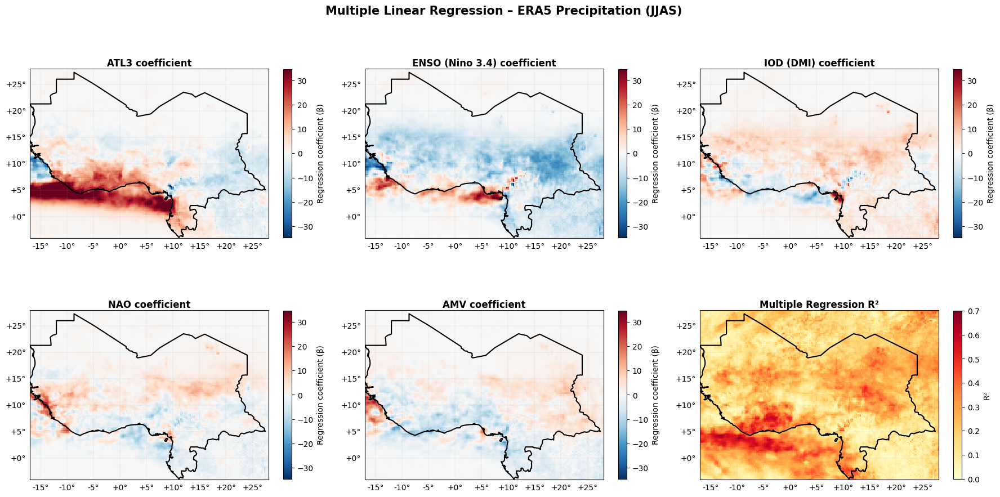

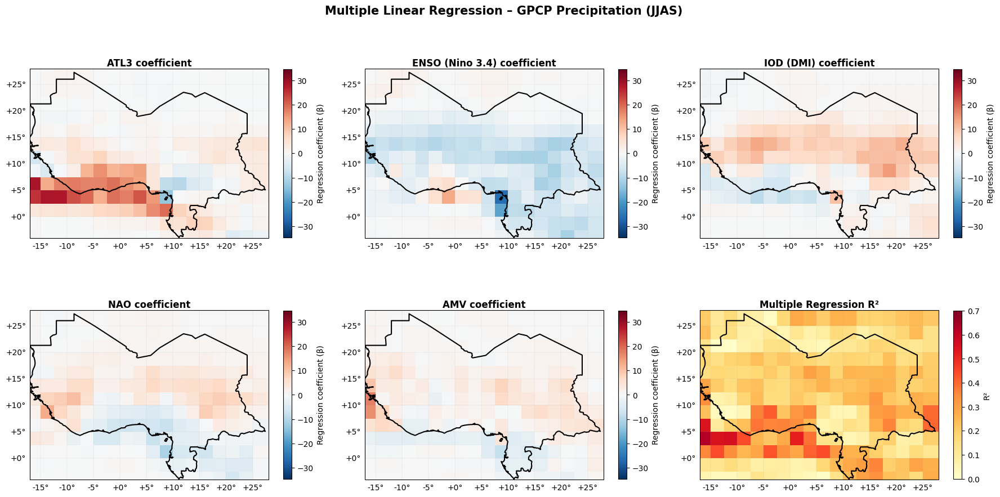

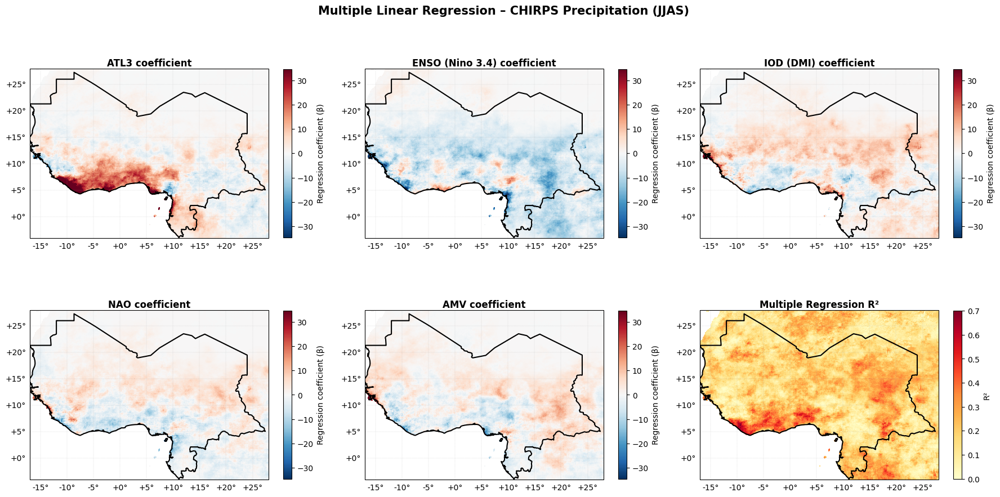

In [72]:
# MLR maps for ERA5, GPCP and CHIRPS

variables = ["ATL3", "Nino34", "DMI", "NAO", "AMV", "R2"]

titles = [
    "ATL3 coefficient",
    "ENSO (Nino 3.4) coefficient",
    "IOD (DMI) coefficient",
    "NAO coefficient",
    "AMV coefficient",
    "Multiple Regression R²"
]

# Calculate common color limits for all predictors

predictors = ["ATL3", "Nino34", "DMI", "NAO", "AMV"]

max_values = []

for results in mlr_results.values():

    for var in predictors:

        data = results["beta"].sel(predictor=var)

        max_values.append(
            np.nanpercentile(np.abs(data.values), 98)
        )

vmax_common = max(max_values)

vmin_common = -vmax_common


for dataset_name, results in mlr_results.items():

    fig, axes = plt.subplots(
        2, 3,
        figsize=(18, 10),
        subplot_kw={"projection": ccrs.PlateCarree()}
    )

    axes = axes.flatten()

    for ax, var, title in zip(axes, variables, titles):

        if var == "R2":
            data = results["R2"]
            cmap = "YlOrRd"
            vmin, vmax = 0, 0.7

        else:
            data = results["beta"].sel(predictor=var)
            vmin, vmax = vmin_common, vmax_common
            cmap = "RdBu_r"

        # Identify coordinate names
        if "longitude" in data.dims:
            lon_dim, lat_dim = "longitude", "latitude"
        else:
            lon_dim, lat_dim = "lon", "lat"

        # Plot GPCP with adjusted grid edges
        if dataset_name == "GPCP":

            lon = data[lon_dim].values
            lat = data[lat_dim].values

            lon_edges = np.concatenate([
                [lon_regions[0]],
                (lon[:-1] + lon[1:]) / 2,
                [lon_regions[1]]
            ])

            lat_edges = np.concatenate([
                [lat_regions[1]],
                (lat[:-1] + lat[1:]) / 2,
                [lat_regions[0]]
            ])

            im = ax.pcolormesh(
                lon_edges,
                lat_edges,
                data.values,
                transform=ccrs.PlateCarree(),
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
                shading="flat"
            )

        else:
            im = ax.pcolormesh(
                data[lon_dim],
                data[lat_dim],
                data,
                transform=ccrs.PlateCarree(),
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
                shading="auto"
            )

        # West Africa external boundary
        ax.add_geometries(
            [wa_union],
            crs=ccrs.PlateCarree(),
            facecolor="none",
            edgecolor="black",
            linewidth=1.5,
            zorder=5
        )

        ax.set_extent(
            [-17, 28, -4, 28],
            crs=ccrs.PlateCarree()
        )

        gl = ax.gridlines(
            draw_labels=True,
            linewidth=0.3,
            alpha=0.5,
            linestyle="--",
            xlocs=np.arange(-15, 28, 5),
            ylocs=np.arange(0, 28, 5)
        )

        gl.top_labels = False
        gl.right_labels = False

        # Signed longitude and latitude labels
        gl.xformatter = FuncFormatter(lambda x, pos: f"{x:+.0f}°")
        gl.yformatter = FuncFormatter(lambda y, pos: f"{y:+.0f}°")

        ax.set_title(title, fontsize=12, fontweight="bold", pad=0)

        cbar = plt.colorbar(
            im,
            ax=ax,
            orientation="vertical",
            pad=0.05,
            shrink=0.59
        )

        if var == "R2":
            cbar.set_label("R²")
        else:
            cbar.set_label("Regression coefficient (β)")

    plt.suptitle(
        f"Multiple Linear Regression – {dataset_name} Precipitation (JJAS)",
        fontsize=15,
        y=0.96,
        fontweight="bold"
    )

    # Adjust subplot spacing
    plt.tight_layout(rect=[0, 0, 1, 1.05], h_pad=0.05)

    # Save figure
    save_dir = "/content/drive/MyDrive/TESI/MLR"
    os.makedirs(save_dir, exist_ok=True)

    filename = f"Multiple_Linear_Regression_{dataset_name}_JJAS_all_indices.png"

    plt.savefig(
        os.path.join(save_dir, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()